# POE: Image Recognition Using Convolutional Neural Networks (CNNs)

Module: Programming for Data Analytics 2

Module Code: PDAN8412

Assessment: Portfolio of Evidence - Image Recognition with CNNs

Dataset: Intel Image Classification

Student Number: ST10082515

Student Name: Luke Antonio Brazier

### Note to the Marker:

1) Training each CNN takes a long time, so I trained my models and saved them along with their training histories (Sections 9.5.1, 11.4 and 11.5.2). The results shown in this notebook are from those training runs. If the training cells are run again, the models will be retrained, and the results may be slightly different due to randomness during training.

2) You will also see my comments throughout the project. These are a combination of my thoughts, as well as clarification on what I have done or shall do throughout the project.

# Table of Contents

### 1. Introduction

### 2. Dataset Selection and Justification

- 2.1 Dataset Overview

- 2.2 Dataset Suitability

- 2.3 Data Quality and Limitations

### 3. Analysis Plan

- 3.1 Exploratory Data Analysis Plan

- 3.2 Data Preparation and Feature Selection Plan

- 3.3 Model Training Plan

- 3.4 Model Evaluation Plan

- 3.5 Model Improvement and Reporting Plan

### 4. Setting Up Environment

- 4.1 Import Libraries

- 4.2 Set Random Seeds and Parameters

- 4.3 Initialising Spark

### 5. Loading the Dataset

- 5.1 Loading the Dataset

- 5.2 Inspecting the Dataset Structure

- 5.3 Dataset Size

- 5.4 Initial Observations

### 6. Exploratory Data Analysis (EDA)

- 6.1 Dataset Completeness

- 6.2 Class Distribution

- 6.3 Image Dimensions and Integrity

- 6.4 Duplicate Images

- 6.5 Visual Inspection

- 6.6 Colour and Brightness

- 6.7 EDA Summary

### 7. Data Cleaning and Preparation

- 7.1 Cleaning the Dataset

- 7.2 Confirming Cleaned Dataset

- 7.3 Create Training, Validation and Test Sets

- 7.4 Resizing the Images

- 7.5 Normalise Pixel Values

- 7.6 Preparing TensorFlow Datasets

- 7.7 Verifying Prepared Data

### 8. Feature Selection and Engineering

- 8.1 Feature Selection Explanation

- 8.2 Data Augmentation

- 8.3 Visualise Augmentation

- 8.4 Explanation of Feature Engineering Decisions

### 9. Baseline CNN Model

- 9.1 Explain Model Architecture

- 9.2 Building the CNN

- 9.3 Displaying Model Summary

- 9.4 Compile the Model

- 9.5 Train the Model

    - 9.5.1 Saving and Loading the Baseline Model and Training History

- 9.6 Initial Training Observations

### 10. Baseline Model Evaluation

- 10.1 Training and Validation Curves

- 10.2 Interpreting Learning Curves

- 10.3 Calculating Performance Metrics

- 10.4 Classification Report

- 10.5 Confusion Matrix

- 10.6 Interpreting Model Performance

- 10.7 Identify Model Shortcomings

### 11. Improved CNN Model

- 11.1 Explaining Proposed Improvements

- 11.2 Building the First Improved CNN

- 11.3 Compiling Improved Model

- 11.4 Train Improved Model

- 11.5 Evaluate Improved Model

    - 11.5.1 Building Second Improved CNN

    - 11.5.2 Train and Evaluate Second Improved CNN

- 11.6 Interpret Improvements

### 12. Model Comparison and Final Evaluation

- 12.1 Comparing Models

- 12.2 Visualising Model Comparisons

- 12.3 Selecting Final Model

- 12.4 Final Test Evaluation

- 12.5 Saving the Final Model

### 13. Conclusion

- 13.1 Summary and Key Findings

- 13.2 Limitations and Future Improvements

### Reference List

## 1. Introduction

The publisher intends to introduce facial recognition technology across its premises. As an initial step, I will develop a Convolutional Neural Network (CNN) to perform image classification using TensorFlow.

I selected the Intel Image Classification dataset because it contains a large collection of labelled images across six categories [1], making it suitable for training and evaluating a CNN [2]. Although the dataset contains natural scenes rather than facial images, it provides an opportunity to demonstrate the image recognition process.

My objective is to explore and prepare the dataset, train a baseline CNN, evaluate its performance and investigate potential improvements. I will use PySpark for data analysis and TensorFlow for model training, with the aim of developing an accurate and reliable image classification model [3].

## 2. Dataset Selection and Justification

### 2.1 Dataset Overview

I selected the Intel Image Classification dataset, available on Kaggle [1]. The dataset contains approximately 25,000 images of natural scenes, originally provided for an image classification challenge [1].

The images are divided into six categories:

1) Buildings

2) Forest

3) Glacier

4) Mountain

5) Sea

6) Street

The images are generally 150 × 150 pixels and contain RGB colour information. The dataset is organised into three main folders:

1) seg_train: Approximately 14,000 labelled training images.

2) seg_test: Approximately 3,000 labelled testing images.

3) seg_pred: Approximately 7,000 unlabelled images for prediction.

I will use the labelled images from seg_train and seg_test for supervised learning. The unlabelled prediction images will not be required for model training or evaluation.

### 2.2 Dataset Suitability

I selected this dataset because it is suitable for training a Convolutional Neural Network (CNN) for multiclass image classification. 

1) Dataset size: The labelled images exceed the minimum requirement of 10,000 records, providing sufficient examples for training and evaluation [1].

2) Labelled images: Each image belongs to one of six categories, making the dataset appropriate for supervised learning [4].

3) RGB information: The images contain colour information that may help distinguish between categories such as forests, glaciers and buildings [5].

4) Visual variety: The images contain different objects, textures, shapes and lighting conditions, allowing the CNN to learn a range of visual features [2].

5) CNN suitability: Convolutional layers can automatically learn spatial patterns from images, reducing the need for manual feature extraction [2].

The dataset provides a practical opportunity to develop, train and evaluate an image-classification model using TensorFlow.

### 2.3 Data Quality and Limitations

Although the dataset is suitable for CNN training, I identified several potential data-quality issues that will need to be investigated during Exploratory Data Analysis (EDA).

1) Incorrect labels: Some images may be assigned to the wrong category, which could affect model training and evaluation [6].

2) Duplicate images: Duplicate images, particularly across training and testing sets, could cause data leakage and produce misleading performance results [7].

3) Class imbalance: Differences in the number of images per category could cause the model to favour more frequently represented classes [8].

4) Image quality: Differences in brightness, image clarity and colour may influence the model’s ability to recognise patterns [9].

5) Similar categories: Certain categories, such as mountains and glaciers, may share visual characteristics, making accurate classification more difficult [9].

I will investigate these issues during EDA and apply appropriate cleaning or preprocessing methods where necessary.

Limitations: The dataset contains natural scenes rather than facial images. Therefore, the model’s performance cannot be used to determine its suitability for actual facial recognition. However, it can demonstrate the underlying image-classification process and provide a foundation for future development.

## 3. Analysis Plan

### 3.1 Exploratory Data Analysis Plan

Before training the CNN, I will conduct Exploratory Data Analysis (EDA) using PySpark and Python to understand the dataset and identify potential issues that could affect model performance.

I plan to investigate the following:

1) Dataset structure and completeness: Examine the dataset structure, image counts, labels and missing values to identify incomplete or invalid records [10].

2) Class distribution: Calculate the number of images in each category to determine whether class imbalance could affect training [8].

3) Image dimensions and integrity: Check image sizes, colour channels and corrupted files to determine whether resizing or cleaning is necessary [11].

4) Duplicate images: Identify exact duplicates and potential overlap between training and testing datasets to prevent data leakage [12].

5) Visual inspection: Display sample images from each category to examine image quality, visual similarities and differences between classes [11].

6) Colour and brightness: Examine colour characteristics and brightness differences to understand whether lighting conditions could influence classification [13].

I will use these findings to guide data cleaning, preprocessing, feature engineering and model evaluation. Each important EDA finding will be linked to a modelling decision.

### 3.2 Data Preparation and Feature Selection Plan

After completing EDA, I will prepare the dataset for CNN training using the following approach:

1) Data cleaning: Corrupt or invalid images will be removed. Exact duplicates will be handled where necessary.

2) Data splitting: I will use the current training and test folders. Around 15% of training images will be held back for validation. The test set will only be used for the final evaluation. Class proportions will be maintained [14].

3) Image resizing: All images will be resized to 150 × 150 pixels to provide uniform input dimensions [11].

4) Pixel normalisation: The pixel values (RGB) will be scaled from 0–255 to 0–1. This supports more stable training of the neural network [11].

5) Feature extraction: Use convolutional layers to automatically learn image features such as edges, textures, shapes and more complex visual patterns [15].

6) Data augmentation: Small rotations, zooming, contrast adjustments and horizontal flipping will be explored to increase training variety and reduce overfitting [16].

Traditional feature selection techniques such as forward or backward elimination are more commonly used with datasets containing individual predictor variables [17]. In the case of images, however, features are extracted automatically using convolutional layers. I intend to use the full RGB information and allow the CNN to extract the relevant image features automatically [15].

Data augmentation will only be applied to training images to avoid altering the validation and testing datasets.

### 3.3 Model Training Plan

I will create a Baseline CNN using TensorFlow/Keras to classify images into six categories.

I will use the following in my model:

1) Input layer: 150 × 150 × 3, which matches the size of the RGB image data that will be used.

2) Convolutional layers: Three Conv2D layers with 32, 64 and 128 filters. These will allow the model to learn increasingly complex image patterns [15].

3) Activation function: ReLU, as this allows training to occur efficiently and introduces non-linearity to the model [18].

4) Pooling layers: MaxPooling2D layers will be used to decrease the spatial dimensions and computational requirements [2].

5) Classification layers: A Flatten layer followed by Dense layers. These are used to combine the features learned above for classification [2].

6) Output layer: A Dense layer with six neurons and Softmax activation. This will produce a probability for each of the six image categories [19].

7) Optimiser: Adam, which adapts the learning rate during optimisation [20].

8) Loss function: Sparse categorical cross-entropy, which is appropriate for multiclass classification with integer labels [21].

9) Batch size: 32. This is a reasonable size that provides a balance between memory usage and training efficiency [22].

10) Epochs: I will initially use 15 epochs. During training, the model will be evaluated on the validation data to monitor performance.

I have chosen a relatively simple CNN architecture to establish baseline performance. I do not wish to add unnecessary complexity to the model at this point. The hyperparameters set above will provide a starting point rather than an assumption that they are the best possible.

During training, both training and validation performance will be tracked to see if any adjustments need to be made. Analysis of the data will be performed using PySpark, while training of the model will be performed using TensorFlow.

### 3.4 Model Evaluation Plan

I will evaluate the CNN using several complementary performance measures rather than relying only on accuracy.

1. Accuracy: Measures the proportion of images correctly classified across the six categories [23].

2. Loss: Measures the difference between predicted probabilities and actual labels, helping assess how effectively the model learns [24].

3. Precision: Measures how many images predicted as a particular category actually belong to that category [23].

4. Recall: Measures how many images belonging to a particular category are correctly identified [23].

5. F1-score: Combines precision and recall, providing a balanced measure of classification performance [23].

6. Confusion matrix: Shows correct and incorrect predictions for each category, helping identify classes that the CNN struggles to distinguish [23].

7. Training and validation curves: Show changes in accuracy and loss across epochs, helping identify overfitting, underfitting and training stability [25].

I will use validation results to assess the baseline model and guide potential improvements. After selecting the final model, I will evaluate it using the untouched test dataset to estimate its performance on unseen images.

I will also examine class-specific results because overall accuracy may hide weaknesses in individual categories.

### 3.5 Model Improvement and Reporting Plan

I will first assess the performance of the Baseline CNN, followed by experimentation to improve this model.

#### Identifying model weaknesses:

Overfitting: A large difference between the training and validation accuracy suggests that the model is learning some patterns that do not generalise well [26].

Underfitting: If both the training and validation accuracy are poor, this could mean that the model is not learning sufficient patterns [26].

Classification errors: Using the class-specific metrics and confusion matrix, I will identify which categories are being less accurately classified.

#### Potential improvements:

Based on the performance of the Baseline CNN, the following improvement techniques could be explored:

1) Data augmentation to provide more diversity to the training data [16].

2) Dropout to reduce overfitting [27].

3) Batch normalisation to support stable training [28].

4) Early stopping to avoid unnecessary training [29].

5) Learning-rate adjustments to improve optimisation [30].

I will then train an improved CNN and compare the two models using the same validation dataset. I will use accuracy, loss, precision, recall and F1-score as metrics for comparison. I will select the model that exhibits the strongest overall performance and generalisation, rather than just the highest training accuracy.

#### Reporting plan:

I will create a separate report in PDF format covering the dataset, data-quality findings, EDA visualisations, data preprocessing, CNN architecture, training and testing, model improvements and performance.

The report will focus on the key findings and limitations rather than simply copying the entire notebook.

## 4. Setting Up Environment

### 4.1 Import Libraries

I will import the Python libraries required for data handling, image processing, visualisation and CNN training. I will use PySpark for data analysis and TensorFlow/Keras to build and evaluate the CNN.

In [ ]:
# Importing the libraries needed:

# Data handling and calculations [31]
import os
import random
import hashlib
import numpy as np
import pandas as pd

# Image processing [11]
from PIL import Image

# Data visualisation 
import matplotlib.pyplot as plt
import seaborn as sns #[32]

# Spark for dataset analysis [33]
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# TensorFlow and Keras for CNN training [11]
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Model evaluation and data splitting [34]
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

### 4.2 Set Random Seeds and Parameters

I will set a random seed to improve the reproducibility of my results. I will also define the image dimensions, batch size and classification categories that will be used throughout the analysis.

In [2]:
# Setting a random seed to make my results more consistent between runs. [35]
seed = 42

random.seed( seed)
np.random.seed( seed)
tf.random.set_seed( seed)

# Defining the image dimensions and batch size for CNN training. [11]
img_height = 150
img_width = 150
batch_size = 32

# Defining the six image categories in the dataset. [11]
class_names = [ "buildings", "forest", "glacier", "mountain", "sea", "street"]

# Checking whether TensorFlow can access a GPU for faster model training. [36]
print( "TensorFlow version:", tf.__version__)
print( "Available GPUs:", tf.config.list_physical_devices( "GPU"))

# Confirming the parameters that will be used throughout the notebook.
print( "Image dimensions:", img_height, "x", img_width)
print( "Batch size:", batch_size)
print( "Number of classes:", len( class_names))

TensorFlow version: 2.21.0
Available GPUs: []
Image dimensions: 150 x 150
Batch size: 32
Number of classes: 6


### 4.3 Initialising Spark

I will initialise a SparkSession to analyse the image dataset using PySpark. Spark will be used to examine the dataset structure, class distributions and data-quality characteristics before training the CNN with TensorFlow.

In [4]:
# Initialising Spark to analyse the image dataset before training my CNN. [37]
spark = (
    SparkSession.builder
    .appName( "Intel_Image_Classification")
    .master( "local[*]")
    .getOrCreate()
)

# Reducing unnecessary Spark messages to keep my notebook output readable. 
spark.sparkContext.setLogLevel( "ERROR") #[38]

# Confirming that the Spark session has started successfully.
print( "Spark version:", spark.version)
print( "Spark session created successfully.")

26/11/18 11:13:45 WARN SparkContext: Another SparkContext is being constructed (or threw an exception in its constructor). This may indicate an error, since only one SparkContext should be running in this JVM (see SPARK-2243). The other SparkContext was created at:
org.apache.spark.api.java.JavaSparkContext.<init>(JavaSparkContext.scala:59)
java.base/jdk.internal.reflect.NativeConstructorAccessorImpl.newInstance0(Native Method)
java.base/jdk.internal.reflect.NativeConstructorAccessorImpl.newInstance(NativeConstructorAccessorImpl.java:77)
java.base/jdk.internal.reflect.DelegatingConstructorAccessorImpl.newInstance(DelegatingConstructorAccessorImpl.java:45)
java.base/java.lang.reflect.Constructor.newInstanceWithCaller(Constructor.java:500)
java.base/java.lang.reflect.Constructor.newInstance(Constructor.java:481)
py4j.reflection.MethodInvoker.invoke(MethodInvoker.java:247)
py4j.reflection.ReflectionEngine.invoke(ReflectionEngine.java:374)
py4j.Gateway.invoke(Gateway.java:238)
py4j.command

Spark version: 4.2.0
Spark session created successfully.


## 5. Loading the Dataset

### 5.1 Loading the Dataset

I will load the Intel Image Classification dataset from my local machine. I will use PySpark to create a DataFrame containing the image file paths and their corresponding labels for analysis.

The dataset contains separate training and testing folders, which I will keep distinct throughout the analysis.

In [ ]:
# Defining the locations of my training and testing images.
train_path = "/Users/bionicpilot/Desktop/PDAN 2/archive-2/seg_train/seg_train"
test_path = "/Users/bionicpilot/Desktop/PDAN 2/archive-2/seg_test/seg_test"

# Using Spark to load the images from both folders. [39]
train_df = spark.read.format( "binaryFile").option( "recursiveFileLookup", True).load( train_path)
test_df = spark.read.format( "binaryFile").option( "recursiveFileLookup", True).load( test_path)

# Displaying five training records to confirm that the images were loaded.
train_df.select( "path", "length").show( 5, truncate=False) #[40]

+-------------------------------------------------------------------------------------+------+
|path                                                                                 |length|
+-------------------------------------------------------------------------------------+------+
|file:/Users/bionicpilot/Desktop/PDAN 2/archive-2/seg_train/seg_train/forest/19124.jpg|27121 |
|file:/Users/bionicpilot/Desktop/PDAN 2/archive-2/seg_train/seg_train/forest/3574.jpg |26831 |
|file:/Users/bionicpilot/Desktop/PDAN 2/archive-2/seg_train/seg_train/forest/13155.jpg|26437 |
|file:/Users/bionicpilot/Desktop/PDAN 2/archive-2/seg_train/seg_train/forest/13765.jpg|26280 |
|file:/Users/bionicpilot/Desktop/PDAN 2/archive-2/seg_train/seg_train/forest/9616.jpg |25955 |
+-------------------------------------------------------------------------------------+------+
only showing top 5 rows


### 5.2 Inspecting the Dataset Structure

I will examine the structure of the dataset using PySpark. This includes identifying the available columns, data types and image categories. Understanding the dataset structure will help me determine whether the data is suitable for further analysis and CNN training.

In [6]:
# Examining the dataset schema and data types.
train_df.printSchema() #[33]

# Displaying the available columns. 
print( "Available columns:", train_df.columns) #[33]

# Extracting the image labels from their folder names. [40], [41]
train_df = train_df.withColumn( "label", F.regexp_extract( "path", r"/([^/]+)/[^/]+$", 1))
test_df = test_df.withColumn( "label", F.regexp_extract( "path", r"/([^/]+)/[^/]+$", 1))

# Displaying the six image categories. [33]
print( "Image labels:")
train_df.select( "label").distinct().show()

# Displaying the data types, including the new label column.
print( "Data types:", train_df.dtypes)

root
 |-- path: string (nullable = true)
 |-- modificationTime: timestamp (nullable = true)
 |-- length: long (nullable = true)
 |-- content: binary (nullable = true)

Available columns: ['path', 'modificationTime', 'length', 'content']
Image labels:


+---------+
|    label|
+---------+
|buildings|
|   forest|
| mountain|
|   street|
|      sea|
|  glacier|
+---------+

Data types: [('path', 'string'), ('modificationTime', 'timestamp'), ('length', 'bigint'), ('content', 'binary'), ('label', 'string')]


### 5.3 Dataset Size

I will calculate the total number of images in both the training and test sets, as well as the number of image classes. This will allow me to determine whether there are sufficient samples to train and evaluate a CNN.

In [7]:
# Counting the images in the training and testing datasets.
train_count = train_df.count()
test_count = test_df.count()

# Calculating the total number of labelled images.
total_count = train_count + test_count

# Counting the number of image categories. [43]
num_classes = train_df.select( "label").distinct().count()

# Displaying the dataset sizes.
print( "Total images:", total_count)
print( "Training images:", train_count)
print( "Testing images:", test_count)
print( "Number of classes:", num_classes)

Total images: 17034
Training images: 14034
Testing images: 3000
Number of classes: 6


### 5.4 Initial Observations

The Intel Image Classification dataset consists of 17,034 labelled images across six categories: buildings, forest, glacier, mountain, sea and street.

There are 14,034 training images and 3,000 testing images in the dataset. This is well above the 10,000 records required by the assignment and provides sufficient observations to train and evaluate a CNN.

I used PySpark to read the data and verify that image file paths, file sizes, modification times and binary image data were all present. I also confirmed that the label for each image could be determined from the name of its containing folder.

The dataset is suitable for the proposed analysis. However, I will still perform exploratory data analysis to examine image quality, class balance and potential duplicates before preparing the images for CNN training.

## 6. Exploratory Data Analysis (EDA)

### 6.1 Dataset Completeness

I will check the training and testing datasets for missing values, missing image labels and invalid categories. This will help me identify any data-quality problems that could affect the accuracy and reliability of my CNN model.

In [8]:
# Combining the training and testing datasets to check all images.
full_df = train_df.unionByName( test_df) #[44]

# Checking each column for missing values. [45]
for column in full_df.columns:
    missing = full_df.filter( F.col( column).isNull()).count()
    print( column, "missing values:", missing)

# Checking whether any image labels are missing or empty. [46]
missing_labels = full_df.filter(
    F.col( "label").isNull() | (F.col( "label") == "")
).count()

# Checking for labels that are not part of the six expected categories. [47]
invalid_labels = full_df.filter(
    F.col( "label").isin( class_names) == False
).count()

# Displaying the results.
print( "Missing labels:", missing_labels)
print( "Invalid categories:", invalid_labels)

path missing values: 0
modificationTime missing values: 0
length missing values: 0


content missing values: 0
label missing values: 0
Missing labels: 0
Invalid categories: 0


#### Interpretation

My analysis identified no missing image content, missing labels or invalid categories across the 17,034 images.

This indicates that the dataset is complete in terms of the fields examined, and no cleaning is required for these issues before CNN training. However, I will still investigate image integrity and potential duplicates in the following sections.

### 6.2 Class Distribution

I will examine the distribution of images across the six categories using PySpark. I will calculate the number and percentage of images in each class and visualise the results using a bar chart.

This will help me identify whether some categories have more images than others, which could affect CNN training and classification performance.

/opt/anaconda3/envs/lstm_env/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


+---------+-----+----------+
|    label|count|percentage|
+---------+-----+----------+
|buildings| 2628|     15.43|
|   forest| 2745|     16.11|
|  glacier| 2957|     17.36|
| mountain| 3037|     17.83|
|      sea| 2784|     16.34|
|   street| 2883|     16.92|
+---------+-----+----------+



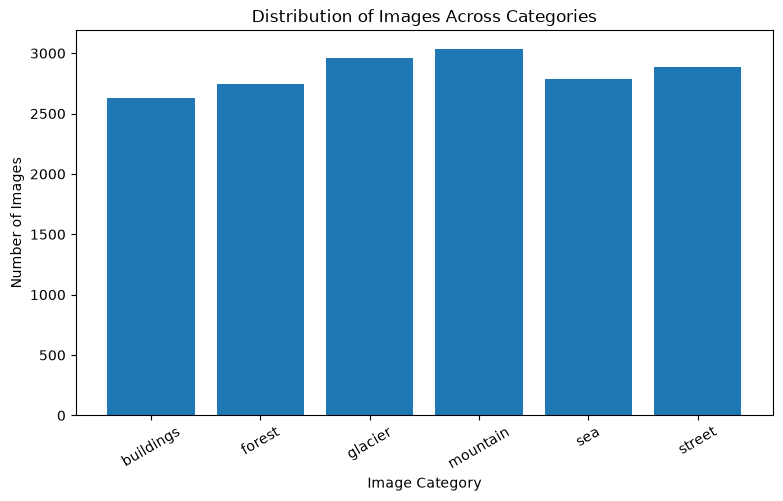

In [9]:
# Counting  the images in each category using Spark.
class_distribution = full_df.groupBy( "label").count().orderBy( "label") #[33]

# Calculating the percentage of images in each category. [48]
class_distribution = class_distribution.withColumn(
    "percentage", F.round( F.col( "count") / total_count * 100, 2)
)

# Displaying the class counts and percentages.
class_distribution.show()

# Converting the results to Pandas to create a bar chart.
class_pd = class_distribution.toPandas()

# Plotting the number of images in each category. [49]
plt.figure( figsize=( 9, 5))
plt.bar( class_pd[ "label"], class_pd[ "count"])

plt.title( "Distribution of Images Across Categories")
plt.xlabel( "Image Category")
plt.ylabel( "Number of Images")
plt.xticks( rotation=30)
plt.show()

#### Interpretation

My analysis shows that the dataset is reasonably balanced across the six image categories. Mountain has the highest proportion (17.83%), while buildings has the lowest (15.43%), a difference of only 2.40 percentage points.

This suggests that class imbalance is unlikely to be a major concern during CNN training. I therefore do not expect to require class-balancing techniques, although I will still evaluate performance across individual categories to identify possible classification weaknesses.

### 6.3 Image Dimensions and Integrity

I will examine the dimensions and colour channels of the images to determine whether they have a consistent format. I will also check for corrupted or unreadable images.

These checks will help me identify whether resizing, colour conversion or removal of invalid images is necessary before CNN training.

In [10]:
# collecting the image paths from Spark for inspection. [50]
image_paths = full_df.select( "path").toPandas()[ "path"]

# Creating lists to store image dimensions and colour channels.
dimensions = []
colour_modes = []
corrupted_images = []

# Examining each image to check its dimensions, colour mode and readability. [50]
for path in image_paths:
    try:
        with Image.open( path.replace( "file:", "")) as img:
            img.load()
            dimensions.append( img.size)
            colour_modes.append( img.mode)

    except Exception:
        corrupted_images.append( path)

# Displaying the most common image dimensions. [51]
print( "Image dimensions:")
print( pd.Series( dimensions).value_counts().head( 10))

# Displaying the different colour modes. [51]
print( "\nColour modes:")
print( pd.Series( colour_modes).value_counts())

# Displaying the number of corrupted or unreadable images.
print( "\nCorrupted images:", len( corrupted_images))

/opt/anaconda3/envs/lstm_env/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


Image dimensions:
(150, 150)    16979
(150, 113)        7
(150, 111)        3
(150, 135)        3
(150, 134)        2
(150, 110)        2
(150, 81)         2
(150, 131)        2
(150, 76)         2
(150, 141)        2
Name: count, dtype: int64

Colour modes:
RGB    17034
Name: count, dtype: int64

Corrupted images: 0


#### Interpretation

About 99.68% of the images (16,979) have dimensions of 150 × 150 pixels, while 0.32% (55 images) have different dimensions. All 17,034 images are in RGB format. No corrupted or unreadable images were found.

These findings show that the dataset can be used for CNN training with minimal preprocessing. I will resize all images to 150 × 150 pixels to provide uniform input dimensions for the network. I will also keep the images in RGB format to preserve colour information. No images need to be removed due to corruption.

### 6.4 Duplicate Images

I will check for exact duplicate images within the dataset and determine whether any duplicates appear in both the training and testing sets.

This is important because duplicate images could cause data leakage and produce misleading model evaluation results. Identifying duplicates will help me determine whether any images need to be removed before CNN training.

In [11]:
# Creating lists to store the image hashes and their dataset groups.
image_hashes = []
image_groups = []

# Calculating a hash for each image to identify exact duplicates. [52]
for path in image_paths:
    with open( path.replace( "file:", ""), "rb") as file:
        image_hash = hashlib.md5( file.read()).hexdigest()
        image_hashes.append( image_hash)

    # Identifying whether the image belongs to the training or testing set.
    if "/seg_train/" in path:
        image_groups.append( "train")
    else:
        image_groups.append( "test")

# Organising the results into a DataFrame. [53]
duplicates_df = pd.DataFrame( {
    "hash": image_hashes,
    "dataset": image_groups
})

# Counting exact duplicate images across the full dataset.
total_duplicates = duplicates_df.duplicated( "hash").sum()

# Checking whether the same images appear in both datasets. [54]
train_hashes = set( duplicates_df[ duplicates_df[ "dataset"] == "train"][ "hash"])
test_hashes = set( duplicates_df[ duplicates_df[ "dataset"] == "test"][ "hash"])

shared_duplicates = len( train_hashes.intersection( test_hashes))

# Displaying the results.
print( "Total duplicate images:", total_duplicates)
print( "Images shared between training and testing:", shared_duplicates)

Total duplicate images: 18
Images shared between training and testing: 3


#### Interpretation

There were 18 exact duplicate image records found. Three image hashes also occurred in both the training and testing datasets.

While this is not an extremely large number, having some images appear in both the training and testing sets creates a risk of data leakage. This could give an overly optimistic result when evaluating my CNN.

As a result, exact duplicates will be removed during data preparation so that an image present in the training set will not also be present in the test set. This should provide a more reliable evaluation of the CNN.

### 6.5 Visual Inspection

I will display sample images from each of the six categories to examine their visual characteristics. I will look for differences and similarities between categories, variations in lighting and any noticeable image-quality issues.

This will help me understand potential challenges the CNN may encounter when learning to classify images.

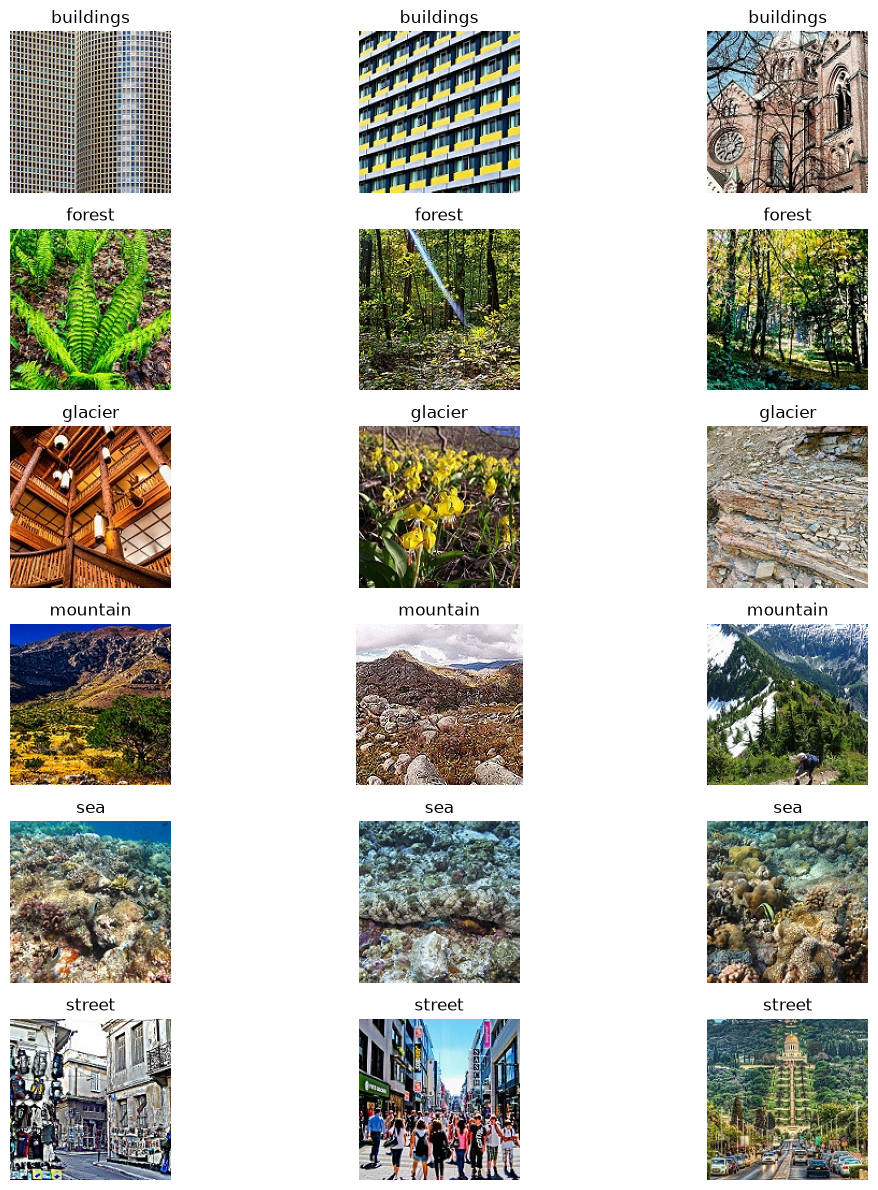

In [12]:
# Creating a figure to display three images from each category. [11]
plt.figure( figsize=( 12, 12))

# Keeping track of each image's position in the figure.
position = 1

# Selecting three images from each category. [33]
for category in class_names:
    sample_paths = train_df.filter( F.col( "label") == category).select( "path").limit( 3).collect()

    # Opening and displaying each image. [50]
    for row in sample_paths:
        image = Image.open( row[ "path"].replace( "file:", ""))

        plt.subplot( 6, 3, position)
        plt.imshow( image)
        plt.title( category)
        plt.axis( "off")

        position = position + 1 #[11]

plt.tight_layout()
plt.show()

#### Interpretation

I can easily distinguish between several image categories, particularly buildings, forests, mountains and streets. However, some images in the glacier class seem rather out of place for that category. This may indicate possible labelling inconsistencies.

I have also noticed variations in image quality, colour and lighting. Such variation can make image classification more challenging.

This suggests that my CNN would benefit from learning a variety of visual features rather than relying only on simple characteristics such as colour. I will also consider data augmentation during training to improve the model’s ability to recognise images under different conditions.

### 6.6 Colour and Brightness

I will examine the colour and brightness characteristics of the images to identify differences between the six categories.

I will use a sample of 100 images per category to calculate average RGB values and brightness. This will help me determine whether retaining colour information is useful and whether data augmentation may improve CNN training.

In [13]:
# Creating a list to store the colour and brightness results.
colour_results = []

# Examining 100 images from each category.[33]
for category in class_names:
    sample_paths = train_df.filter( F.col( "label") == category).select( "path").limit( 100).collect()

    for row in sample_paths:
        # Opening the image and converting it into numerical RGB values. [5], [50]
        image = Image.open( row[ "path"].replace( "file:", "")).convert( "RGB")
        pixels = np.array( image)

        # Calculating the average red, green, blue and brightness values. [54]
        red = pixels[ :, :, 0].mean()
        green = pixels[ :, :, 1].mean()
        blue = pixels[ :, :, 2].mean()
        brightness = pixels.mean()

        colour_results.append([ category, red, green, blue, brightness])

# Organising the results into a DataFrame.
colour_df = pd.DataFrame( colour_results, columns=[ "Category", "Red", "Green", "Blue", "Brightness"]
)

# Calculating the average values for each category.
colour_summary = colour_df.groupby( "Category").mean().round( 2)

# Displaying the results.
print( colour_summary)

              Red   Green    Blue  Brightness
Category                                     
buildings  118.55  114.64  107.42      113.54
forest      99.14  107.94   59.14       88.74
glacier    118.22  131.53  135.15      128.30
mountain   109.52  116.45  114.15      113.38
sea        106.36  119.29  120.64      115.43
street     119.72  111.89  102.51      111.37


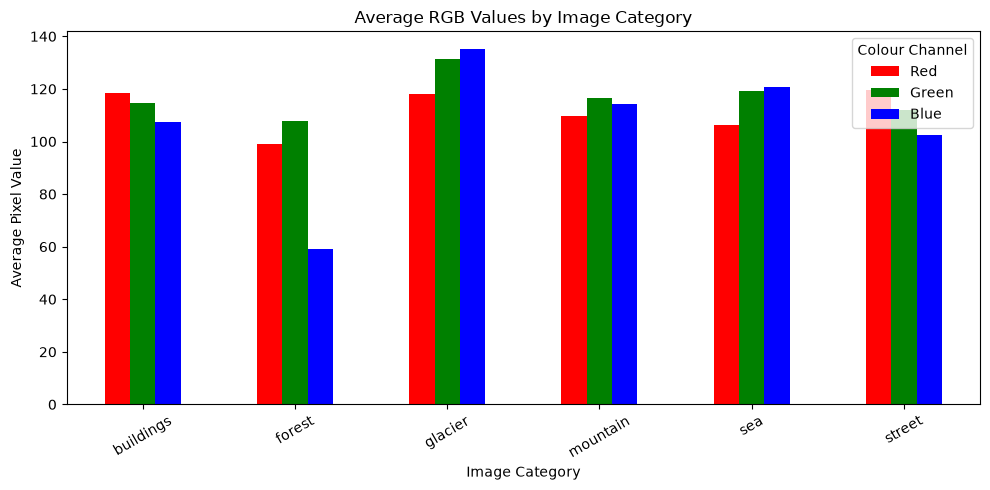

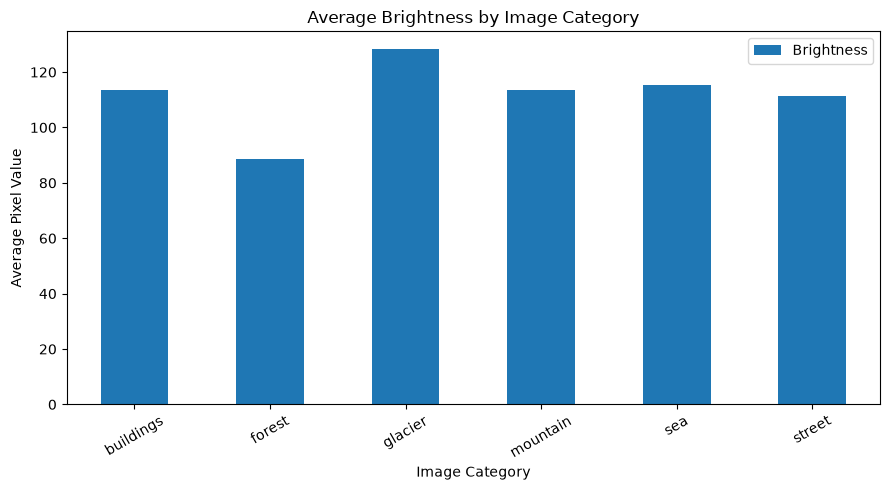

In [ ]:
# Comparing the average RGB values across the six categories. [55]
colour_summary[[ "Red", "Green", "Blue"]].plot(
    kind="bar", figsize=( 10, 5), color=[ "red", "green", "blue"]
)

plt.title( "Average RGB Values by Image Category")
plt.xlabel( "Image Category")
plt.ylabel( "Average Pixel Value")
plt.xticks( rotation=30)
plt.legend( title="Colour Channel")
plt.tight_layout()
plt.show()

# Comparing the average brightness of each category. [55]
colour_summary[[ "Brightness"]].plot( kind="bar", figsize=( 9, 5))

plt.title( "Average Brightness by Image Category")
plt.xlabel( "Image Category")
plt.ylabel( "Average Pixel Value")
plt.xticks( rotation=30)
plt.tight_layout()
plt.show()


#### Interpretation

There were variations in brightness and colour between the six image categories. Glaciers were found to have the highest average brightness (128.30) and forests the lowest (88.74). There were also differences between the categories in terms of their RGB values, especially in blue and green.

Based on these results, I believe that RGB images should be retained due to the potential value of colour in image classification. However, some image categories do share similar RGB values, meaning that colour alone is not sufficient for classification.

Thus, I will retain the RGB images and consider contrast augmentation during CNN training to help the model recognise images under different lighting conditions.

### 6.7 EDA Summary

The following are the findings from my Exploratory Data Analysis, which will influence how the data is prepared and used to train my CNN.

1) Dataset Completeness

There are no missing images, missing labels or invalid categories. No data cleaning will be needed for these issues.

2) Class Distribution

There is a fairly even distribution of images across the six categories, ranging from 15.43% (buildings) to 17.83% (mountain). This suggests that class imbalance is unlikely to be a major concern during CNN training.

3) Image Dimensions and Integrity

99.68% of the images have dimensions of 150 × 150 pixels. All images use RGB colour channels, and no corrupted images were found. I will resize all images to 150 × 150 pixels to provide uniform input dimensions for my CNN.

4) Duplicate Images

There are 18 exact duplicate image records, including 3 image hashes shared between the training and testing datasets. I will address these duplicates during data cleaning, as they may result in data leakage and affect the reliability of my evaluation.

5) Visual Inspection

I can see that there are noticeable differences between the categories. However, some images appear unusual for their assigned labels. This may indicate potential classification challenges and inconsistencies in labelling.

6) Colour and Brightness

For 100 images in each category, I observed variations in brightness and RGB values. Glacier images were generally brighter, while forest images were darker. I will retain the RGB images and consider contrast augmentation to improve performance under different lighting conditions.

#### Overall Conclusion

This dataset appears suitable for CNN training but will need some preparation. I will address the duplicate images, resize and normalise the images, and create a validation set.

These steps should help improve the reliability of both the training process and final model evaluation.

## 7. Data Cleaning and Preparation

### 7.1 Cleaning the Dataset

During my exploratory analysis, I found no corrupted images, missing labels or invalid categories. Therefore, no records need to be removed for these reasons.

I found 18 exact duplicate records, including some images that appear in both the training and testing datasets. These duplicates will be removed to minimise the risk of data leakage and provide a more reliable evaluation of my CNN.

Where duplicate images appear in both datasets, the original training images will be kept, while the corresponding testing copies will be removed.

In [ ]:
# Adding the image paths to the duplicate records.
duplicates_df[ "path"] = image_paths.values

# Separating the training and testing image records.
clean_train = duplicates_df[ duplicates_df[ "dataset"] == "train"].copy()
clean_test = duplicates_df[ duplicates_df[ "dataset"] == "test"].copy()

# Removing repeated images within each dataset. [56]
clean_train = clean_train.drop_duplicates( subset="hash")
clean_test = clean_test.drop_duplicates( subset="hash")

# Identifying the unique image hashes in the cleaned training dataset.
train_hashes = set( clean_train[ "hash"])

# Removing testing images that also appear in the training dataset. [57]
clean_test = clean_test[ clean_test[ "hash"].isin( train_hashes) == False]

# Displaying the remaining records.
print( "Clean training images:", len( clean_train))
print( "Clean testing images:", len( clean_test))

Clean training images: 14019
Clean testing images: 2997


### 7.2 Confirming Cleaned Dataset

I will compare the original and cleaned dataset sizes to confirm how many images were removed. I will also check that no exact duplicates remain and investigate whether any duplicate images had conflicting labels.

This will help me verify that the dataset is ready to be divided into training, validation and testing sets.

In [18]:
# Calculating the number of images remaining after cleaning.
clean_train_count = len( clean_train)
clean_test_count = len( clean_test)
clean_total = clean_train_count + clean_test_count

# Calculating how many images were removed.
removed_images = total_count - clean_total

# Displaying the original and cleaned dataset sizes.
print( "Original images:", total_count)
print( "Removed images:", removed_images)
print( "Final images:", clean_total)

print( "\nTraining images:", clean_train_count)
print( "Testing images:", clean_test_count)

# Checking whether any duplicate images remain.
cleaned_df = pd.concat([ clean_train, clean_test]) #[58]

remaining_duplicates = cleaned_df.duplicated( subset="hash").sum() #[53]

print( "\nRemaining duplicates:", remaining_duplicates)

# Checking whether identical images originally had different labels.
duplicates_df[ "label"] = duplicates_df[ "path"].str.split( "/").str[ -2] #[59]

conflicting_labels = duplicates_df.groupby( "hash")[ "label"].nunique() #[60]
conflicting_count = ( conflicting_labels > 1).sum() 

print( "Duplicate images with conflicting labels:", conflicting_count)

Original images: 17034
Removed images: 18
Final images: 17016

Training images: 14019
Testing images: 2997

Remaining duplicates: 0
Duplicate images with conflicting labels: 13


#### Interpretation

I have removed 18 exact duplicate images, and the dataset has gone from 17,034 images to 17,016 images. I have verified that there are now no exact duplicate images in the dataset. There are 14,019 images used for training and 2,997 images used for testing.

There were also 13 duplicate image hashes that had different category labels. As only the first instance of a duplicate image is kept, there is a chance that the remaining labels do not reflect the correct category. Thus, there is a possibility of incorrect labelling remaining in the dataset.

The risk of data leakage and conflicting training examples has been reduced through the data cleaning process. The dataset is now ready for the next preparation stage. There is still the issue of possible incorrect labelling within the dataset.

### 7.3 Create Training, Validation and Test Sets

I will divide my cleaned training dataset into training and validation sets, using 15% of the images for validation. I will use stratified splitting to maintain similar class proportions in both sets.

I will keep the existing testing dataset separate so that it can provide an unbiased final evaluation of my CNN. The training set will be used for model fitting, while the validation set will help me monitor performance and make improvements.

In [19]:
# Splitting the cleaned training images into training and validation sets. [14]
train_data, val_data = train_test_split(
    clean_train,
    test_size=0.15,
    random_state=42,
    stratify=clean_train[ "path"].str.split( "/").str[ -2]
)

# Keeping the cleaned testing images separate for final evaluation.
test_data = clean_test.copy()

# Displaying the number of images in each dataset.
print( "Training images:", len( train_data))
print( "Validation images:", len( val_data))
print( "Testing images:", len( test_data))
print( "Total images:", len( train_data) + len( val_data) + len( test_data))

Training images: 11916
Validation images: 2103
Testing images: 2997
Total images: 17016


#### Interpretation

I divided the cleaned dataset into 11,916 training images, 2,103 validation images and 2,997 testing images.

I used stratified splitting to maintain similar class proportions in the training and validation sets. I also kept the testing dataset separate to ensure that it can be used for an independent final evaluation.

This approach allows me to train the CNN, monitor its performance and make improvements without using the testing data during model development.

### 7.4 Resizing the Images

I will resize all images to 150 × 150 pixels to ensure consistent input dimensions for my CNN.

My exploratory analysis showed that most images already had these dimensions, although 55 images differed in size. Resizing will ensure that every image can be processed using the same CNN input shape.

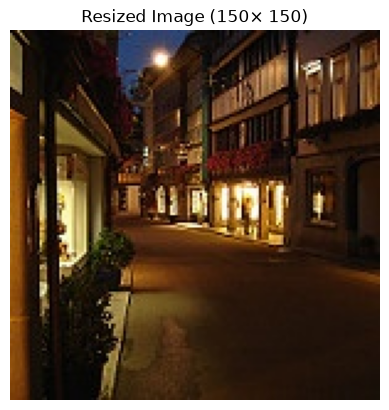

Resized image shape: (150, 150, 3)


In [20]:
# Creating a function to load and resize an image. [50]
def resize_image( path):
    with Image.open( path.replace( "file:", "")) as img:
        img = img.convert( "RGB")
        img = img.resize(( 150, 150))
        return np.array( img)

# Testing the resizing function using one training image.
sample_path = train_data.iloc[ 0][ "path"]
resized_image = resize_image( sample_path)

# Displaying the resized image and its dimensions. [11]
plt.imshow( resized_image)
plt.title( "Resized Image (150× 150)")
plt.axis( "off")
plt.show()

print( "Resized image shape:", resized_image.shape)

#### Interpretation

The resizing function successfully produced an image with dimensions of 150 × 150 pixels and three RGB colour channels.

This confirms that the function can prepare images in the consistent format required by my CNN. I will apply the same resizing process to all images when creating the TensorFlow datasets.

### 7.5 Normalise Pixel Values

I will normalise the image pixel values by dividing them by 255, converting their original range of 0–255 into a range of 0–1.

Normalisation helps the CNN process the image data more consistently and can improve training stability. I will apply the same normalisation process to the training, validation and testing images [11].

In [22]:
# Creating a function to normalise image pixel values. [11]
def normalise_image( image):
    return image.astype( "float32") / 255.0

# Testing the normalisation function using the resized image from Section 7.4.
normalised_image = normalise_image( resized_image)

# Comparing the pixel values before and after normalisation.
print( "Original minimum pixel value:", resized_image.min())
print( "Original maximum pixel value:", resized_image.max())

print( "\nNormalised minimum pixel value:", normalised_image.min())
print( "Normalised maximum pixel value:", normalised_image.max())

Original minimum pixel value: 0
Original maximum pixel value: 255

Normalised minimum pixel value: 0.0
Normalised maximum pixel value: 1.0


#### Interpretation

The original image had pixel values ranging from 0 to 255. After normalisation, these values ranged from 0.0 to 1.0, confirming that the function worked correctly.

This scaling prepares the image data for CNN training by ensuring that pixel values are within a consistent range. I will apply the same normalisation process to all images when creating the TensorFlow datasets.

### 7.6 Preparing TensorFlow Datasets

For training, validation and testing, I will create TensorFlow datasets from the cleaned image records.

I will use the resizing and normalisation functions created in the earlier sections so that all images have the same dimensions and their pixel values are normalised.

I will batch the images so multiple images are processed at a time, and I will prefetch the data as this can improve data-loading efficiency during CNN training. I will shuffle the training data but keep the validation and testing datasets separate.

In [23]:
# Creating a function to load, resize and normalise each image. [50]
def load_image( path, label):
    image = resize_image( path) 
    image = normalise_image( image) #[11]
    return image, label

# Creating a function to prepare a TensorFlow dataset.
def create_dataset( data, shuffle=False):

    # Extracting the image paths and convert category names into numbers.
    paths = data[ "path"].tolist()
    labels = data[ "path"].str.split( "/").str[ -2] #[59]
    labels = [ class_names.index( label) for label in labels]

    # Loading and preparing the images.
    images = []
    for path in paths:
        image = resize_image( path) #[50]
        image = normalise_image( image) #[11]
        images.append( image)

    # Converting the images and labels into a TensorFlow dataset. [31]
    dataset = tf.data.Dataset.from_tensor_slices(( np.array( images), labels))

    # Shuffling only the training dataset. [31]
    if shuffle:
        dataset = dataset.shuffle( buffer_size=1000, seed=42)

    # Grouping images into batches and preparing batches in advance. [31]
    dataset = dataset.batch( batch_size)
    dataset = dataset.prefetch( tf.data.AUTOTUNE)

    return dataset

# Creating the training, validation and testing datasets.
train_ds = create_dataset( train_data, shuffle=True)
val_ds = create_dataset( val_data)
test_ds = create_dataset( test_data)

# Confirming that the datasets were created.
print( "Training dataset created:", train_ds is not None)
print( "Validation dataset created:", val_ds is not None)
print( "Testing dataset created:", test_ds is not None)

Training dataset created: True
Validation dataset created: True
Testing dataset created: True


#### Interpretation

I have created training, validation and testing datasets using TensorFlow.

Images have been resized and pixel normalisation has been performed. The categories have been converted to numerical labels. Images have been batched in batches of 32. The training dataset has been shuffled and prefetching has been applied to facilitate training of a CNN.

The datasets are now ready for use with a CNN. In the following section, I will examine the batch sizes, image pixel ranges and dataset shapes.

### 7.7 Verifying Prepared Data

I will verify that my training, validation and testing datasets have been prepared correctly before developing the CNN.

I will check the image dimensions, label shapes, pixel value ranges and number of images in each dataset. These checks will help me identify any remaining preprocessing problems before model training.

In [24]:
# Extracting one batch of images and labels from the training dataset. [31]
for images, labels in train_ds.take( 1):
    print( "Image batch shape:", images.shape)
    print( "Label batch shape:", labels.shape)

    # Checking the minimum and maximum pixel values. [61]
    print( "\nMinimum pixel value:", np.min( images.numpy()))
    print( "Maximum pixel value:", np.max( images.numpy()))

    # Checking the range of numerical labels. [61]
    print( "\nMinimum label:", np.min( labels.numpy()))
    print( "Maximum label:", np.max( labels.numpy()))

# Confirming the number of images in each dataset.
print( "\nTraining images:", len( train_data))
print( "Validation images:", len( val_data))
print( "Testing images:", len( test_data))

# Confirming the total number of prepared images.
total_images = len( train_data) + len( val_data) + len( test_data)
print( "Total images:", total_images)

Image batch shape: (32, 150, 150, 3)
Label batch shape: (32,)

Minimum pixel value: 0.0
Maximum pixel value: 1.0

Minimum label: 0
Maximum label: 5

Training images: 11916
Validation images: 2103
Testing images: 2997
Total images: 17016


#### Interpretation

My verification confirmed that the image batches have the expected shape of (32, 150, 150, 3), while the label batches have a shape of (32,). This indicates that each batch contains 32 RGB images with dimensions of 150 × 150 pixels and one numerical label per image.

The pixel values range from 0.0 to 1.0, confirming successful normalisation. The numerical labels range from 0 to 5, representing the six image categories.

The prepared dataset contains 11,916 training images, 2,103 validation images and 2,997 testing images, giving a total of 17,016 images.

Based on these checks, my data is correctly formatted and ready for CNN training.

## 8. Feature Selection and Engineering

### 8.1 Feature Selection Explanation

In a CNN, the relevant features of an image are automatically extracted during the training process. There is no need to perform manual feature selection, as the convolutional layers will learn the relevant features from the image [15].

The early convolutional layers tend to extract low-level image features such as colour, texture and edges. Successively deeper layers combine these low-level features to produce more complex patterns such as mountains, trees, buildings and other image content that is relevant to my six image categories [15].

I have chosen to preserve the original RGB colour information as there may be colour differences that can be used to distinguish between the image categories [13]. Glaciers, for instance, can have large blue or white areas, while forests can have large areas of green vegetation. I have also performed exploratory analysis and found variations in brightness and colour between the image categories.

Traditional feature selection methods, such as forward selection and backward elimination, were not used as individual image pixels are not independent explanatory variables in the same way as features in a traditional tabular dataset [17]. Instead, the relevant spatial features are learned directly from the images by the CNN.

### 8.2 Data Augmentation

I will use data augmentation to create small variations in my training images. This should help my CNN recognise patterns in images under different conditions and reduce the risk of overfitting.

I will use augmentation techniques such as contrast adjustments, zooming, small rotations and horizontal flipping. All of these should be appropriate for my image categories. They create realistic variations while generally preserving the original image content.

Augmentation will only be used during training. The validation and testing images will remain unchanged to allow for a more reliable evaluation of the model.

In [25]:
# Creating a data augmentation pipeline for my training images. [16]
data_augmentation = keras.Sequential( [
    layers.RandomFlip( "horizontal"),
    layers.RandomRotation( 0.05),
    layers.RandomZoom( 0.1),
    layers.RandomContrast( 0.1)
], name="data_augmentation")

# Confirming that the augmentation pipeline was created.
print( "Data augmentation pipeline created successfully.")

Data augmentation pipeline created successfully.


### 8.3 Visualise Augmentation

I will visualise the effects of data augmentation by comparing an original training image with four randomly augmented versions.

This will allow me to examine how horizontal flipping, rotation, zooming and contrast adjustments change the appearance of an image while generally preserving its original category.

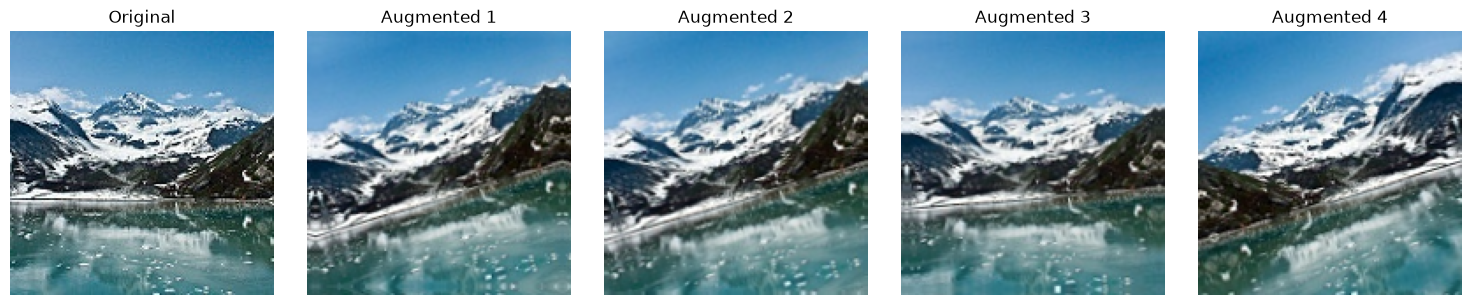

Original category: glacier


In [26]:
# Selecting one image from my training dataset. [31]
for images, labels in train_ds.take( 1):
    original_image = images[ 0]
    original_label = labels[ 0]

# Creating a figure with five images. [16]
plt.figure( figsize=( 15, 3))

# Displaying the original image.
plt.subplot( 1, 5, 1)
plt.imshow( original_image)
plt.title( "Original")
plt.axis( "off")

# Generating and displaying four augmented versions. [16]
for i in range( 4):
    augmented_image = data_augmentation( original_image[ None, ...], training=True)

    plt.subplot( 1, 5, i + 2)
    plt.imshow( np.clip( augmented_image[ 0], 0, 1))
    plt.title( f"Augmented { i + 1}")
    plt.axis( "off")

plt.tight_layout()
plt.show()

# Displaying the image category.
print( "Original category:", class_names[ int( original_label)])

#### Interpretation

The visualisation shows the original glacier image alongside four augmented versions. The transformations introduced variations in image orientation, positioning, zoom and appearance.

Despite these changes, the snow-covered mountains and surrounding landscape remained recognisable, preserving the original glacier category.

This demonstrates how data augmentation can introduce variation into the training images while retaining important visual features. These variations may help my CNN generalise better to unfamiliar images and reduce overfitting.

### 8.4 Explanation of Feature Engineering Decisions

#### Image Representation

I have decided to use the RGB colour information of the images and to resize all images to 150 × 150 pixels. This results in uniform image dimensions for the neural network while still retaining spatial and colour information which might be useful in distinguishing between the six image categories. The pixel values have also been normalised between 0 and 1, which can support more stable CNN training.

#### Data Augmentation

I have decided to use small rotations, zooming, contrast adjustments and horizontal flipping as augmentation techniques on the training data. I performed visualisations as part of Section 8.3 and found that these transformations altered the appearance of a glacier image but still retained its recognisable features. I believe this type of augmentation may help the model generalise to new images and reduce overfitting.

#### Training Data Only

I plan to use data augmentation only during model training. The validation and testing images will be preprocessed in the same way (resizing and normalisation) but will not undergo any augmentation. This will allow me to evaluate my model on consistent, unaugmented images and prevent augmented data from affecting the evaluation results.

## 9. Baseline CNN Model

In this section, I will develop and train a baseline Convolutional Neural Network (CNN) to classify images into six categories. I will explain the model architecture, construct and compile the CNN using TensorFlow/Keras, and train it using the prepared training dataset.

I will monitor training and validation performance to establish a baseline against which I can evaluate future model improvements.

### 9.1 Explain Model Architecture

I will create a Baseline CNN for classifying images into six categories: buildings, forest, glacier, mountain, sea and street. I will use convolutional, pooling and dense layers, ending with a softmax output layer.

#### Convolutional Layers

I will use three convolutional layers. They will each have 32, 64 and 128 filters respectively. These layers will automatically learn features in the images such as edges, textures and more complex patterns [15]. I will also use the ReLU activation function to allow the model to learn non-linear relationships [18].

#### Pooling Layers

I will use a max-pooling layer after each convolutional layer. This will shrink the size of the feature maps but will still preserve important information. This will also decrease the number of computations required [2].

#### Dense Layers

I will pass the features through a Flatten layer before passing them through a Dense layer. The Dense layer will allow combinations of the features learned and help identify patterns for each image category [2].

#### Softmax Output Layer

I will end the network in a Dense layer with six neurons corresponding to the six image categories. I will use a softmax activation function so a probability is given to each category and the most probable class can be predicted [19].

#### Purpose of the Architecture

This architecture has been chosen to establish a baseline for image classification. The training and validation results will be used to find any weaknesses in the model, and improvements can then be tested to see if they improve the model in classifying unfamiliar images.

### 9.2 Building the CNN

I will implement my Baseline CNN using TensorFlow/Keras. The CNN will consist of 3 convolutional layers where the number of filters increases through the network in order to extract features from the images [2].

Max-pooling layers will be implemented to reduce the size of the feature maps. A Flatten layer will be followed by a Dense layer to enable classification. A final softmax layer will output predictions for the six image categories [11].

The network will remain relatively simple in order to establish a baseline before improvements can be made.

In [41]:
# Creating my baseline CNN using a sequential architecture. [11]
baseline_model = keras.Sequential( [

    # Defining the input shape for my RGB images.
    layers.Input( shape=( 150, 150, 3)),

    # Using convolutional layers to learn visual features. [11]
    layers.Conv2D( 32,( 3, 3), activation="relu"),
    layers.MaxPooling2D(( 2, 2)),

    layers.Conv2D( 64, ( 3, 3), activation="relu"),
    layers.MaxPooling2D( (2, 2)),

    layers.Conv2D( 128, ( 3, 3), activation="relu"),
    layers.MaxPooling2D(( 2, 2)),

    # flattening the feature maps and combining the learned features. [11]
    layers.Flatten(),
    layers.Dense( 128, activation="relu"),

    # using softmax to predict one of my six image categories. [19]
    layers.Dense( 6, activation="softmax")

])

print( "Baseline CNN created successfully.")

Baseline CNN created successfully.


### 9.3 Displaying Model Summary

I will display a summary of my baseline CNN to examine its layer structure, output shapes and parameter counts.

This will help me understand how the image dimensions change as they pass through the network and how many parameters the model needs to learn during training.

In [42]:
# Displaying the architecture and parameter counts of my baseline CNN.
baseline_model.summary() #[11]

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,829,126 (18.42 MB)

 Trainable params: 4,829,126 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

#### Interpretation

The description from my model summary shows that the Baseline CNN consists of three convolutional layers, three max-pooling layers, a Flatten layer and two Dense layers, including the final classification layer.

The model has 4,829,126 parameters, and all of these are trainable. The Dense layer directly after the Flatten layer has the majority of these parameters.

Because there are a relatively large number of parameters in this model, there is a potential for overfitting to occur. I will test this by training the Baseline CNN and then comparing the training and validation results.

### 9.4 Compile the Model

I will use the Adam optimiser, sparse categorical cross-entropy as the loss function and accuracy as the metric used to assess the performance of my Baseline CNN [11].

#### Optimiser: Adam

Adam is an optimiser that adapts the learning rate for each parameter during training. It is commonly used within neural networks and so is a good choice for my Baseline CNN [20].

#### Loss Function: Sparse Categorical Cross-Entropy

I have chosen sparse categorical cross-entropy as my loss function because my task is a classification problem with six mutually exclusive categories, which are identified by integer values ranging from 0 to 5. Sparse categorical cross-entropy computes the loss between the true category labels and the predicted probabilities for each category [21].

#### Evaluation Metric: Accuracy

Accuracy will be used as a performance metric because it measures the proportion of images predicted in the correct category [23]. From my exploratory data analysis, I have seen that my six categories are fairly evenly distributed, so accuracy will offer a useful initial performance metric for my model.

I will also use precision, recall and F1-score as performance metrics to provide a more in-depth analysis of my classification results [23].

In [43]:
# Compiling my baseline CNN using Adam, sparse categorical cross-entropy and accuracy. [11]
baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Confirming that the model has been compiled.
print( "Baseline CNN compiled successfully.")

Baseline CNN compiled successfully.


In [44]:
# Checking the training and validation datasets before retraining.
print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))

for images, labels in val_ds.take(1):
    print("Image shape:", images.shape)
    print("Minimum pixel value:", images.numpy().min())
    print("Maximum pixel value:", images.numpy().max())

print("Model compiled:", baseline_model.optimizer is not None)

Training batches: 373
Validation batches: 66
Image shape: (32, 150, 150, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Model compiled: True


### 9.5 Train the Model

I will use my training data to train my Baseline CNN. I will use my validation set to gauge performance.

I will first train the model for 15 epochs with a batch size of 32. I will record the training and validation loss and accuracy during training to determine the model’s ability to learn.

I will then use these results to identify any issues such as underfitting or overfitting and establish a baseline for further improvements.

The testing data will be kept separate until the final model evaluation.

In [45]:
# Training the baseline CNN first so that I can measure its performance before making improvements. [11]
baseline_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

# Confirming that training has finished.
print( "Baseline CNN training completed.")

Epoch 1/15


/opt/anaconda3/envs/lstm_env/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


373/373 ━━━━━━━━━━━━━━━━━━━━ 45s 118ms/step - accuracy: 0.6401 - loss: 0.9479 - val_accuracy: 0.7461 - val_loss: 0.7083
Epoch 2/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 46s 124ms/step - accuracy: 0.7768 - loss: 0.6042 - val_accuracy: 0.7651 - val_loss: 0.6621
Epoch 3/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 45s 122ms/step - accuracy: 0.8364 - loss: 0.4557 - val_accuracy: 0.7694 - val_loss: 0.6805
Epoch 4/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 45s 120ms/step - accuracy: 0.8811 - loss: 0.3280 - val_accuracy: 0.8027 - val_loss: 0.6823
Epoch 5/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 45s 121ms/step - accuracy: 0.9240 - loss: 0.2071 - val_accuracy: 0.8008 - val_loss: 0.7764
Epoch 6/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 45s 121ms/step - accuracy: 0.9563 - loss: 0.1299 - val_accuracy: 0.8060 - val_loss: 0.8683
Epoch 7/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 45s 121ms/step - accuracy: 0.9709 - loss: 0.0828 - val_accuracy: 0.8074 - val_loss: 0.9285
Epoch 8/15
373/373 ━━━━━━━━━━━━━━━━━━━━ 45s 121ms/step - accuracy: 0.9783 - loss: 0.0682 - val

#### 9.5.1 Saving and Loading the Baseline Model and Training History

I will save my trained baseline CNN and its training history to preserve the results obtained during training.

Saving the model allows me to reuse its learned weights without repeating the training process. Saving the training history allows me to analyse the recorded accuracy and loss values without retraining.

This also helps maintain consistency when I rerun parts of my notebook.

In [ ]:
# Saving my retrained baseline CNN under a new filename. [63]
baseline_model.save( "baseline_cnn_retrained.keras")

# Saving the training history from the 15 epochs. [66]
history_df_new = pd.DataFrame( baseline_history.history)
history_df_new.to_csv( "baseline_history_retrained.csv", index=False)

# Confirming that both files were saved.
print( "Retrained baseline CNN and history saved successfully.")
print( "Number of training epochs:", len( history_df_new))
print( "Final validation accuracy:", history_df_new[ "val_accuracy"].iloc[ -1])

Retrained baseline CNN and history saved successfully.
Number of training epochs: 15
Final validation accuracy: 0.804564893245697


### 9.6 Initial Training Observations

The Baseline CNN was trained on the training set for 15 epochs, and performance on the separate validation set was recorded.

#### Training Performance

Training accuracy went from 64.01% in epoch 1 to 98.96% in epoch 15. Training loss went from 0.9479 to 0.0277. This shows that the CNN gradually learned to recognise patterns in the training images.

#### Validation Performance

Validation accuracy started to rise and reached a peak of around 81.12% in epoch 10. After that, it varied before ending at 80.46%. Validation loss increased from 0.7083 to 1.4256.

#### Initial Observations

There appears to be a significant gap between the final training accuracy (98.96%) and validation accuracy (80.46%). This could suggest that the Baseline CNN is overfitting the training data. This means that the CNN recognises patterns in the training data very well but does not appear to generalise as well to unseen images.

This will be explored in more depth in Section 10 using the training and validation loss and accuracy graphs, other classification metrics and the confusion matrix. These results will then be used to guide improvements to the CNN.

## 10. Baseline Model Evaluation

In this section, I will evaluate the performance of my baseline CNN using the validation dataset.

I will examine the training and validation accuracy and loss curves to identify potential overfitting or underfitting. I will then calculate accuracy, precision, recall and F1-score to assess the model’s classification performance.

I will also examine the classification report and confusion matrix to identify which image categories the model classifies most accurately and where errors occur.

Finally, I will use these findings to identify weaknesses in my baseline CNN and determine which improvements may be necessary.


### 10.1 Training and Validation Curves

I will display the training and validation loss and accuracy for each of the 15 training epochs.

The accuracy curves will display the classification performance of the model during training, whilst the loss curves will display how prediction errors changed [25].

I will also look at the difference between training and validation performance in order to assess whether or not my Baseline CNN generalises well to unseen images, or if there is evidence of overfitting [26].

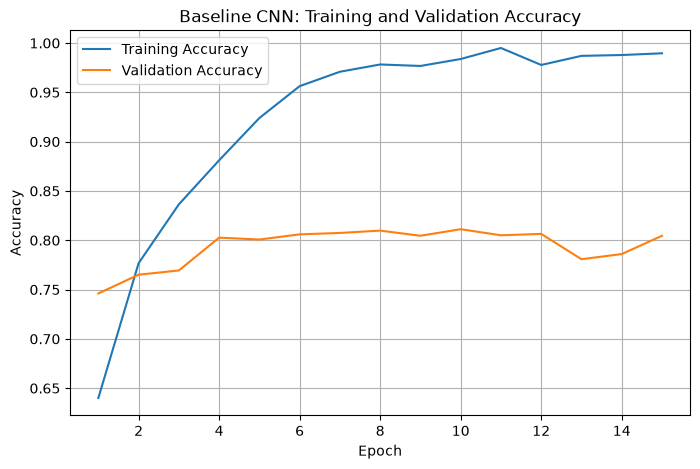

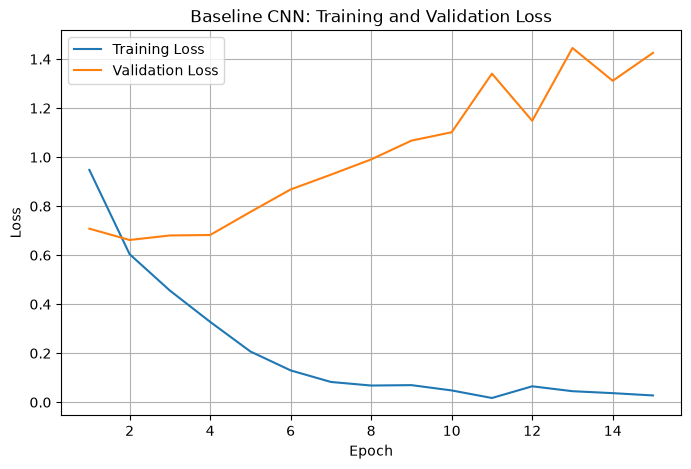

In [50]:
# Loading my saved training history to plot the baseline CNN training results.
history_df = pd.read_csv( "baseline_history_retrained.csv")

# Creating the epoch numbers for the horizontal axis.
epochs = range( 1, len( history_df) + 1)

# Plotting training and validation accuracy. [11], [62]
plt.figure( figsize=( 8, 5))

plt.plot( epochs, history_df[ "accuracy"], label="Training Accuracy")
plt.plot( epochs, history_df[ "val_accuracy"], label="Validation Accuracy")

plt.title( "Baseline CNN: Training and Validation Accuracy")
plt.xlabel( "Epoch")
plt.ylabel( "Accuracy")
plt.legend()
plt.grid( True)
plt.show()

# Plotting training and validation loss. [11]
plt.figure( figsize=( 8, 5))

plt.plot( epochs, history_df[ "loss"], label="Training Loss")
plt.plot( epochs, history_df[ "val_loss"], label="Validation Loss")

plt.title( "Baseline CNN: Training and Validation Loss")
plt.xlabel( "Epoch")
plt.ylabel( "Loss")
plt.legend()
plt.grid( True)
plt.show()

### 10.2 Interpreting Learning Curves

Using the training and validation curves, I can assess the performance of my Baseline CNN on the training and unseen validation data.

#### Generalisation

The final training set accuracy is 98.96%, whereas the final validation set accuracy is 80.46%. The gap between these is around 18.50 percentage points, suggesting that the CNN does not generalise as well to unseen data as it performs on the training data.

#### Overfitting

There is clear evidence of overfitting. The training accuracy continues to rise during training, however, the validation accuracy reaches around 81.12% at epoch 10 before fluctuating. The training loss has reduced to 0.0277, while the validation loss has increased to 1.4256. This suggests that the model is increasingly fitting the training data without similar improvements in validation performance.

#### Underfitting

There does not seem to be an issue with underfitting. The training accuracy is very high and the training loss is very low. This suggests that the CNN does have the ability to learn patterns from the training data.

#### Training Stability

During the initial epochs, the training accuracy rises steadily, and towards the end of training, the accuracy remains very high. However, the validation accuracy fluctuates during training. The validation loss, on the other hand, increases quite significantly. This suggests that the model does learn well from the training data, however, its performance on the validation data becomes less stable as training proceeds.

#### Overall Interpretation

My Baseline CNN does learn to classify the images in the training set. However, there is a large difference between the performance on the training data and the performance on the unseen validation data. This suggests that overfitting is occurring. In the following sections, I will analyse the performance of the model on each category as well as the types of misclassification occurring. I will then consider methods to improve the performance of the model.

### 10.3 Calculating Performance Metrics

I will evaluate my baseline CNN using predictions from the validation dataset. I will also calculate accuracy, precision, recall and F1-score to assess the model’s classification performance.

I selected macro averaging for precision, recall and F1-score because my dataset contains six reasonably balanced image categories. Macro averaging calculates each metric separately for every class before taking the average, giving all categories equal importance.

These metrics will provide a more detailed assessment of model performance than accuracy alone.

The testing dataset will remain untouched.

In [51]:
# Loading my saved baseline CNN for evaluation. [63]
baseline_model = keras.models.load_model( "baseline_cnn_retrained.keras")

# Collecting my validation images and labels together.
val_images = []
val_labels = []

for images, labels in val_ds:
    val_images.append( images.numpy())
    val_labels.append( labels.numpy())

# Combining the validation images and labels.
val_images = np.concatenate( val_images, axis=0)
val_true_labels = np.concatenate( val_labels, axis=0)

# Generating predictions using the same validation image order. [11]
val_predictions = baseline_model.predict( val_images)

# Selecting the class with the highest predicted probability for each image. [64]
val_predicted_labels = np.argmax( val_predictions, axis=1)

# Calculating the baseline CNN's performance metrics. [65]
val_accuracy = accuracy_score( val_true_labels, val_predicted_labels)
val_precision = precision_score( val_true_labels, val_predicted_labels, average="macro", zero_division=0)
val_recall = recall_score( val_true_labels, val_predicted_labels, average="macro", zero_division=0)
val_f1 = f1_score( val_true_labels, val_predicted_labels, average="macro", zero_division=0)

# Displaying the results as percentages.
print( f"Validation Accuracy: { val_accuracy:.2%}")
print( f"Validation Precision: { val_precision:.2%}")
print( f"Validation Recall: { val_recall:.2%}")
print( f"Validation F1-score: { val_f1:.2%}")

66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step
Validation Accuracy: 80.46%
Validation Precision: 81.21%
Validation Recall: 80.44%
Validation F1-score: 80.35%


#### Interpretation

My baseline CNN achieved a validation accuracy of 80.46%, macro precision of 81.21%, macro recall of 80.44% and macro F1-score of 80.35%.

The four metrics are relatively similar, indicating reasonably balanced overall classification performance across the six categories. However, these averages do not reveal which individual categories perform best or worst.

I will investigate class-specific performance using the classification report and confusion matrix in the following sections.

### 10.4 Classification Report

I will generate a classification report using the validation predictions from Section 10.3.

The report will display precision, recall, F1-score and support for each of the six image categories. Support represents the number of actual validation images belonging to each category.

This will allow me to identify differences in classification performance between categories and determine which classes require further investigation.

In [ ]:
# Generating a classification report for my six image categories. [65]
report = classification_report(
    val_true_labels,
    val_predicted_labels,
    labels=range( len( class_names)),
    target_names=class_names,
    zero_division=0
)

# Displaying the classification report.
print( report)

              precision    recall  f1-score   support

   buildings       0.86      0.65      0.74       329
      forest       0.90      0.94      0.92       340
     glacier       0.74      0.80      0.77       361
    mountain       0.83      0.73      0.78       376
         sea       0.83      0.81      0.82       341
      street       0.72      0.90      0.80       356

    accuracy                           0.80      2103
   macro avg       0.81      0.80      0.80      2103
weighted avg       0.81      0.80      0.80      2103



#### Interpretation

The forest category appears to be performing the best in my results, as it has the highest recall (0.94) and highest F1-score (0.92). This implies that the majority of forest images were classified correctly.

Buildings have the lowest recall (0.65) and lowest F1-score (0.74). This means that around 35% of actual building images were classified incorrectly.

Street has the lowest value for precision (0.72). This means that some images were classified as streets when they were not actually street images.

Classification performance appears to differ across categories. I will now look at the confusion matrix to determine which categories are most frequently confused.

### 10.5 Confusion Matrix

I will use a confusion matrix to look at both correctly and incorrectly classified images from the validation set using my Baseline CNN.

A confusion matrix shows the actual image categories against the predicted image categories. Correct classifications will be shown along the diagonal, and incorrect classifications will be shown outside the diagonal.

I will use this to look at commonly confused image categories and identify any potential issues with the classification performance of my model.

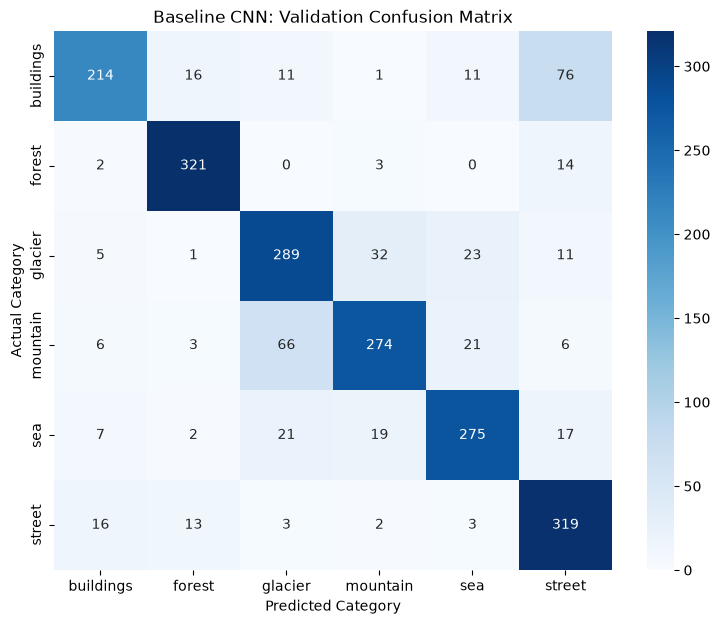

In [ ]:
# Calculating the confusion matrix using my validation predictions. [34]
cm = confusion_matrix( val_true_labels, val_predicted_labels)

# Visualising the confusion matrix to identify correct and incorrect predictions. [72]
plt.figure( figsize=( 9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title( "Baseline CNN: Validation Confusion Matrix")
plt.xlabel( "Predicted Category")
plt.ylabel( "Actual Category")
plt.show()

#### Interpretation

My confusion matrix shows that the Baseline CNN does a fairly good job at classifying the validation images. The largest numbers of correctly classified images appear along the diagonal of the matrix.

Forest performed particularly well, with 321 out of 340 images being classified correctly.

The largest classification errors occurred between mountain and glacier, where 66 mountain images were identified as glaciers. There were also 76 building images identified as streets and 16 street images identified as buildings.

This could be due to some visual features being common across different image categories, making it difficult for the CNN to identify the differences between them. I will explore these classification errors in more detail in Section 10.6.

### 10.6 Interpreting Model Performance

#### Strongest-Performing Classes

My Baseline CNN performed with an 80.46% accuracy on the validation set and a macro F1-score of 80.35%.

Forest was the best-performing category with a recall of 0.94 and an F1-score of 0.92. A total of 321 out of 340 forest images were correctly predicted. This seems to indicate that the model picks up on features that can separate forests from the other categories.

#### Weakest-Performing Classes

Buildings were the worst-performing category, with the lowest recall (0.65) and lowest F1-score (0.74). This means that the model struggled to correctly predict some of the building images.

Street had the lowest precision of 0.72 but a fairly high recall of 0.90. A total of 319 out of 356 street images were correctly predicted. This indicates that the model successfully predicts the majority of street images but also makes some mistakes where it incorrectly labels an image from another category as a street.

#### Common Classification Errors

Looking at the confusion matrix, two major classification errors were found:

1) 66 mountain images were predicted as glaciers.

2) 76 building images were predicted as streets.

Additionally, 32 glacier images were predicted as mountains.

These classification errors may be attributed to similarities between some categories. Glaciers and mountains can both have snow and rocky terrain. Streets and buildings can both have similar urban features.

#### Connections to EDA Findings

From my EDA, I found that all six categories were fairly even in number. This reduces the likelihood of performance issues being mainly caused by a large imbalance in the number of samples between categories.

Also, from the EDA, I found variations in visual appearance, lighting and scenery within the categories. This could complicate classification, as some images could be harder to classify because of these differences.

From my brightness analysis, I found that the average brightness of forest images was 88.74, while glacier images had the highest average brightness at 128.30. Such brightness differences could be useful in distinguishing between categories, but brightness alone does not account for the performance of the model.

My Baseline CNN performed fairly well at classification but had issues with categories that were similar in visual appearance. Given this, as well as the overfitting identified in Section 10.2, there is a reason to attempt to improve the model.

### 10.7 Identify Model Shortcomings

My baseline CNN achieved a validation accuracy of 80.46%. Although this demonstrates reasonable classification performance, several weaknesses were identified.

1) Overfitting

The model achieved a final training accuracy of 98.96%, compared with a validation accuracy of 80.46%. This difference of approximately 18.50 percentage points indicates overfitting, suggesting that the model learned the training images well but struggled to generalise to unseen validation images [26].

2) Classification Errors

The confusion matrix revealed difficulties distinguishing between visually similar categories, particularly mountains and glaciers, as well as streets and buildings. These errors reduced the model’s overall classification performance.

3) Model Complexity

The baseline CNN contained approximately 4.83 million trainable parameters, with most concentrated in the dense layer following flattening. This relatively large number of parameters may have contributed to overfitting [26].

4) Limited Generalisation Techniques

The baseline model did not use data augmentation, dropout or other explicit regularisation techniques. These methods could potentially improve generalisation and reduce overfitting [27].

#### Proposed Improvements

To address these weaknesses, I will develop an improved CNN using data augmentation, dropout and adjustments to the model architecture. I will compare its performance against the baseline using validation data.

The test dataset will remain untouched until the final model has been selected, ensuring an independent evaluation of its performance.

## 11. Improved CNN Model

Here I will create an improved CNN that will address some of the problems observed during the evaluation of my Baseline CNN.

I will aim to improve generalisation, decrease overfitting and increase classification performance on the validation set.

I will make improvements to the model architecture and training process and justify these changes. I will then compare these results to those of my Baseline CNN.

I will again use the same training and validation sets to ensure a fair comparison. The test set will be kept separate until the final model evaluation.

### 11.1 Explaining Proposed Improvements

For my Baseline CNN, the training set achieved 98.96% accuracy, whilst the validation set achieved 80.46%. This large gap between training and validation accuracy suggests the model is overfitting and has not been able to generalise as well to unseen images [26].

The following improvements will be introduced to try to address these issues.

1) Data Augmentation

The data augmentation techniques outlined in Section 8.2 will be used. These include zooming, contrast adjustments, rotation and horizontal flipping. These will help to introduce variation into the training data so that the model will learn to recognise more general image characteristics instead of overfitting to individual images [16].

2) Dropout

Dropout will be introduced to randomly disable a number of neurons during training. This should assist with reducing overfitting by reducing the model’s dependence on individual neurons [27].

3) Batch Normalisation

Batch normalisation will be used to stabilise training. This normalises intermediate activation values in the network and could aid training stability and convergence [28].

4) Early Stopping

For my Baseline CNN, the highest validation accuracy was achieved before the final training epoch. However, there was a significant increase in validation loss during later epochs [29].

Early stopping will be introduced to monitor validation loss and stop training once no further improvement is observed. This should assist in reducing overfitting as well as unnecessary training epochs.
I will introduce early stopping to monitor validation loss and stop training when performance no longer improves. This should help prevent unnecessary training and limit overfitting.

5) Model Architecture Adjustments

My Baseline CNN had approximately 4.83 million trainable parameters. The majority of these parameters were in the dense layer following the flattening layer. I plan to replace the flattening layer with global average pooling. This will reduce the number of parameters and may also assist with generalisation [15].

6) Learning Rate

I will initially use the default learning rate of the Adam optimiser (0.001). This will allow the focus to be placed on the impact of the regularisation methods and changes to the model architecture without introducing further adjustments [30].

#### Expected Outcome

These improvements should assist in reducing overfitting and may improve performance on the validation set. The improved CNN will be evaluated using the same training and validation sets as the Baseline CNN.

The test set will be kept separate until a final model has been chosen.

### 11.2 Building the First Improved CNN

I will build my first improved CNN using data augmentation, batch normalisation, dropout and global average pooling to address the overfitting observed in my baseline model.

In [ ]:
# Building my improved CNN using the augmentation layers created in Section 8.2. [11]
improved_model = keras.Sequential([
    layers.Input( shape=( 150, 150, 3)),

    # Applying random transformations to training images. [16]
    data_augmentation,

    # Extracting basic image features. [11]
    layers.Conv2D( 32, ( 3, 3), activation="relu"),
    layers.BatchNormalization(), #[28]
    layers.MaxPooling2D(( 2, 2)),

    # Learning more complex image features.
    layers.Conv2D( 64,( 3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(( 2, 2)),

    # Extracting higher-level image features.
    layers.Conv2D( 128, ( 3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(( 2, 2)),

    # Reducing the number of parameters compared with flattening. [67]
    layers.GlobalAveragePooling2D(),

    # Using dropout to help reduce overfitting. [27]
    layers.Dense( 128, activation="relu"),
    layers.Dropout( 0.5),

    # Predicting one of the six image categories. [11]
    layers.Dense( 6, activation="softmax")
])

# Displaying the improved model's architecture.
improved_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 148, 148, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 72, 72, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 34, 34, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,430 (435.27 KB)

 Trainable params: 110,982 (433.52 KB)

 Non-trainable params: 448 (1.75 KB)

#### Model Architecture Findings

My improved CNN contains 111,430 total parameters, compared with 4,829,126 in the baseline model. This represents a reduction of approximately 97.7%.

The reduction was mainly achieved by replacing the flattening layer with global average pooling, which substantially reduced the number of parameters required by the dense layer.

I also introduced data augmentation, batch normalisation and dropout to help reduce overfitting and improve generalisation. Although the improved model is considerably smaller, its effectiveness will only be determined after training and validation.

### 11.3 Compiling Improved Model

I will compile my improved CNN using the Adam optimiser, sparse categorical cross-entropy loss function and accuracy as the evaluation metric. I will retain the same compilation settings as my baseline CNN to ensure a consistent comparison.

The Adam optimiser will use its default learning rate of 0.001. This allows me to evaluate the effects of the architectural improvements and regularisation techniques without introducing additional changes to the learning rate.

In [ ]:
# Compiling my improved CNN using the same settings as the baseline model. [68]
improved_model.compile(
    optimizer=keras.optimizers.Adam( learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=[ "accuracy"]
)

print( "Improved CNN compiled successfully.")

Improved CNN compiled successfully.


### 11.4 Train Improved Model

I will train my improved CNN using the same training and validation datasets as my baseline model to ensure a fair comparison. I will allow a maximum of 20 training epochs and introduce early stopping to monitor validation loss.

Early stopping will stop training if validation loss does not improve for three consecutive epochs. I will also restore the weights from the epoch with the lowest validation loss.

The improved model will use data augmentation and dropout during training to help reduce overfitting and improve generalisation. I will evaluate whether these changes improve validation performance compared with my baseline CNN.

In [ ]:
# Using early stopping to reduce unnecessary training and limit overfitting. [69]
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Training my improved CNN using the same training and validation datasets. [68]
improved_history = improved_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[ early_stopping]
)

Epoch 1/20


/opt/anaconda3/envs/lstm_env/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


373/373 ━━━━━━━━━━━━━━━━━━━━ 74s 196ms/step - accuracy: 0.6007 - loss: 1.0313 - val_accuracy: 0.1916 - val_loss: 2.8860
Epoch 2/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 74s 198ms/step - accuracy: 0.7236 - loss: 0.7440 - val_accuracy: 0.6567 - val_loss: 0.8468
Epoch 3/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 74s 199ms/step - accuracy: 0.7617 - loss: 0.6513 - val_accuracy: 0.6714 - val_loss: 0.9601
Epoch 4/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 72s 192ms/step - accuracy: 0.7873 - loss: 0.5851 - val_accuracy: 0.5930 - val_loss: 1.2051
Epoch 5/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 72s 193ms/step - accuracy: 0.8040 - loss: 0.5512 - val_accuracy: 0.3928 - val_loss: 1.5142


In [ ]:
# Saving my improved CNN with its restored best weights. [63]
improved_model.save( "improved_cnn.keras")

# Saving the training history for later analysis. [66]
improved_history_df = pd.DataFrame( improved_history.history)
improved_history_df.to_csv( "improved_history.csv", index=False)

print( "Improved model and training history saved successfully.")

Improved model and training history saved successfully.


### 11.5 Evaluate Improved Model

I will use the same validation dataset used for my Baseline CNN to allow for a fair comparison.

I will use accuracy, precision, recall and F1-score to determine classification performance.

I will also plot the training and validation loss and accuracy to see if there is a decrease in overfitting with the improved model.

Due to early stopping restoring the weights from the epoch with the lowest validation loss, I will use this restored model and not the model from the final epoch of training.

The test set will be kept separate until a final model has been selected.

In [ ]:
# Generating predictions using my improved CNN and validation dataset.[11]
improved_predictions = improved_model.predict( val_ds)

# Selecting the category with the highest predicted probability. [64]
improved_predicted_labels = np.argmax( improved_predictions, axis=1)

# Calculating the improved CNN's validation performance metrics. [65]
improved_accuracy = accuracy_score( val_true_labels, improved_predicted_labels)
improved_precision = precision_score( val_true_labels, improved_predicted_labels, average="macro", zero_division=0)
improved_recall = recall_score( val_true_labels, improved_predicted_labels, average="macro", zero_division=0)
improved_f1 = f1_score( val_true_labels, improved_predicted_labels, average="macro", zero_division=0)

# Displaying the validation results as percentages.
print( f"Validation Accuracy: { improved_accuracy:.2%}")
print( f"Validation Precision: { improved_precision:.2%}")
print( f"Validation Recall: { improved_recall:.2%}")
print( f"Validation F1-score: { improved_f1:.2%}")

66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step
Validation Accuracy: 65.67%
Validation Precision: 71.70%
Validation Recall: 66.30%
Validation F1-score: 63.89%


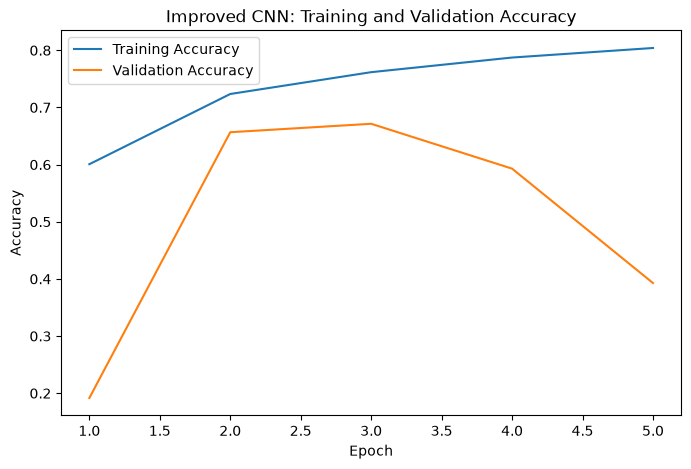

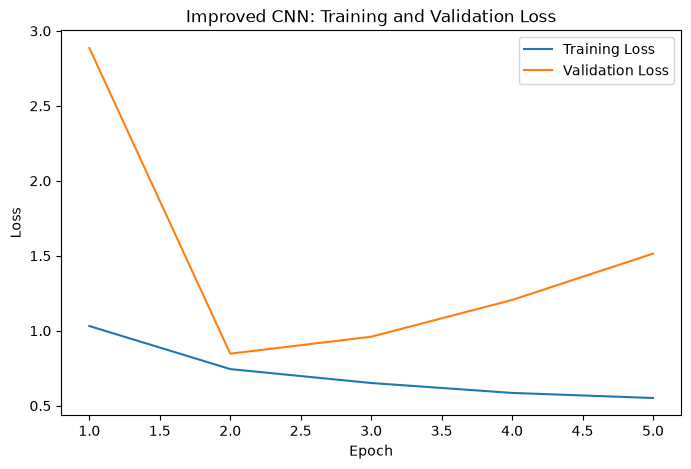

In [54]:
# Loading my saved improved CNN training history.
improved_history_df = pd.read_csv( "improved_history.csv")

# Identifying the number of completed training epochs.
epochs = range( 1, len( improved_history_df) + 1)

# Plotting training and validation accuracy. [11, 62]
plt.figure( figsize=(8, 5))

plt.plot( epochs, improved_history_df[ "accuracy"], label="Training Accuracy")
plt.plot( epochs, improved_history_df[ "val_accuracy"], label="Validation Accuracy")

plt.title( "Improved CNN: Training and Validation Accuracy")
plt.xlabel( "Epoch")
plt.ylabel( "Accuracy")
plt.legend()
plt.show()

# Plotting training and validation loss. [11, 62]
plt.figure( figsize=( 8, 5))

plt.plot( epochs, improved_history_df[ "loss"], label="Training Loss")
plt.plot( epochs, improved_history_df[ "val_loss"], label="Validation Loss")

plt.title( "Improved CNN: Training and Validation Loss")
plt.xlabel( "Epoch")
plt.ylabel( "Loss")
plt.legend()
plt.show()

#### Evaluation Findings

The precision for the First Improved CNN was 71.70%, the recall was 66.30%, the F1-score was 63.89% and the validation accuracy was 65.67%.

This is significantly lower than the Baseline CNN’s F1-score of 80.35% and validation accuracy of 80.46%.

The training curves showed that training accuracy steadily increased to 80.40% at epoch 5. The validation accuracy started to decrease after epoch 3, while the validation loss started to rise after epoch 2.

Early stopping was triggered after 5 epochs, and the weights from epoch 2 (the epoch with the lowest validation loss) were restored.

Despite the introduction of regularisation techniques and a reduction in the number of parameters, performance on the validation set did not improve during this experiment.

It would appear that further adjustments are required to achieve better generalisation.

In [ ]:
# My first improved CNN performed worse than my baseline model. Validation accuracy dropped from 80.46% to 65.67%, and the F1-score also decreased.
# Validation performance became worse as training continued. Perhaps reduced the model's complexity too much, or batch normalisation contributed to the unstable validation results.

# Will try another model with slightly more learning capacity, remove batch normalisation, and retain augmentation, dropout and early stopping.
# Will then check whether these adjustments improve validation performance.

#### 11.5.1 Building Second Improved CNN

After the poor validation results achieved with the First Improved CNN, I will now create a Second Improved CNN.

I will remove batch normalisation to see if this contributed to instability in the validation results.

I will also replace global average pooling with flattening. I will use a smaller dense layer than in the Baseline CNN. This will allow the model to have a greater learning capacity than the First Improved CNN.

Dropout and data augmentation will continue to be used in an effort to reduce overfitting [27].

In [ ]:
# Building a second improved CNN with a revised architecture. [11]
improved_model_2 = keras.Sequential([
    layers.Input( shape=( 150, 150, 3)),

    # Retaining data augmentation to introduce variation during training. [16]
    data_augmentation,

    # Extracting image features using three convolutional layers. [11]
    layers.Conv2D( 32, ( 3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D( 64, ( 3, 3), activation="relu"),
    layers.MaxPooling2D(( 2, 2)),

    layers.Conv2D( 128, (3, 3), activation="relu"),
    layers.MaxPooling2D( (2, 2)),

    # Using flattening to retain more information from the feature maps. [11]
    layers.Flatten(),

    # Using a smaller dense layer than my baseline model.
    layers.Dense( 64, activation="relu"),

    # Applying dropout to help reduce overfitting. [27]
    layers.Dropout( 0.5),

    # Classifying images into six categories.
    layers.Dense( 6, activation="softmax")
])

# Displaying the model architecture and parameter count.
improved_model_2.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │     2,367,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,461,190 (9.39 MB)

 Trainable params: 2,461,190 (9.39 MB)

 Non-trainable params: 0 (0.00 B)

#### Architecture Observation

My second improved CNN contains 2,461,190 trainable parameters, approximately 49% fewer than the baseline model.

This represents an increase in model complexity compared with my first improved CNN, which contained only 111,430 total parameters.

I introduced this adjustment to investigate whether increasing the model’s learning capacity, while retaining data augmentation and dropout, could improve validation performance.

#### 11.5.2 Train and Evaluate Second Improved CNN

I will now compile and train my second improved CNN using the same training and validation datasets as my previous models.

I will use the Adam optimiser with a learning rate of 0.001, sparse categorical cross-entropy as the loss function and accuracy as the evaluation metric.

I will also retain early stopping to prevent unnecessary training when validation loss stops improving. The model will be trained for a maximum of 20 epochs, with the best weights restored after training.

Once training is complete, I will save the model and its training history before calculating validation accuracy, precision, recall and F1-score.

This will allow me to determine whether the architectural adjustments improved classification performance compared with my baseline and first improved CNN.

The test dataset will remain untouched until the final model has been selected.

In [ ]:
# Compiling my second improved CNN using the same settings as my previous models. [68]
improved_model_2.compile(
    optimizer=keras.optimizers.Adam( learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=[ "accuracy"]
)

print( "Second improved CNN compiled successfully.")

Second improved CNN compiled successfully.


In [ ]:
# Using early stopping to monitor validation loss and limit overfitting. [69]
early_stopping_2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# training my second improved CNN using the same training and validation datasets. [68]
improved_history_2 = improved_model_2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[ early_stopping_2]
)

Epoch 1/20


/opt/anaconda3/envs/lstm_env/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


373/373 ━━━━━━━━━━━━━━━━━━━━ 46s 120ms/step - accuracy: 0.4556 - loss: 1.3347 - val_accuracy: 0.5097 - val_loss: 1.2971
Epoch 2/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 45s 121ms/step - accuracy: 0.5831 - loss: 1.0679 - val_accuracy: 0.6553 - val_loss: 0.8805
Epoch 3/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 45s 121ms/step - accuracy: 0.6392 - loss: 0.9569 - val_accuracy: 0.6981 - val_loss: 0.8474
Epoch 4/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 45s 120ms/step - accuracy: 0.6732 - loss: 0.8675 - val_accuracy: 0.7808 - val_loss: 0.6377
Epoch 5/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 45s 120ms/step - accuracy: 0.6921 - loss: 0.8306 - val_accuracy: 0.7765 - val_loss: 0.6385
Epoch 6/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 45s 121ms/step - accuracy: 0.7033 - loss: 0.7823 - val_accuracy: 0.7565 - val_loss: 0.6871
Epoch 7/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 45s 121ms/step - accuracy: 0.7300 - loss: 0.7348 - val_accuracy: 0.8046 - val_loss: 0.5593
Epoch 8/20
373/373 ━━━━━━━━━━━━━━━━━━━━ 45s 121ms/step - accuracy: 0.7505 - loss: 0.6799 - val

In [ ]:
# Saving my second improved CNN with its restored best weights. [63]
improved_model_2.save( "improved_cnn_2.keras")

# Saving the training history so I can analyse it without retraining. [66]
improved_history_df_2 = pd.DataFrame( improved_history_2.history)
improved_history_df_2.to_csv( "improved_history_2.csv", index=False)

print( "Second improved model and training history saved successfully.")

Second improved model and training history saved successfully.


In [ ]:
# Generating predictions using my second improved CNN. [68]
improved_predictions_2 = improved_model_2.predict( val_ds)

# Selecting the category with the highest predicted probability. [64]
improved_predicted_labels_2 = np.argmax( improved_predictions_2, axis=1)

# Calculating the validation performance metrics. [65]
improved_accuracy_2 = accuracy_score( val_true_labels, improved_predicted_labels_2)
improved_precision_2 = precision_score( val_true_labels, improved_predicted_labels_2, average="macro", zero_division=0)
improved_recall_2 = recall_score( val_true_labels, improved_predicted_labels_2, average="macro", zero_division=0)
improved_f1_2 = f1_score( val_true_labels, improved_predicted_labels_2, average="macro", zero_division=0)

# Displaying my results as percentages.
print( f"Validation Accuracy: { improved_accuracy_2:.2%}")
print( f"Validation Precision: { improved_precision_2:.2%}")
print( f"Validation Recall: { improved_recall_2:.2%}")
print( f"Validation F1-score: { improved_f1_2:.2%}")

66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step
Validation Accuracy: 81.93%
Validation Precision: 82.29%
Validation Recall: 82.09%
Validation F1-score: 82.04%


#### Validation Findings

My Second Improved CNN had a validation accuracy of 81.93%, a precision of 82.29%, recall of 82.09% and an F1-score of 82.04%.

This is better than both my Baseline CNN and First Improved CNN.

Accuracy has increased by 1.47 percentage points compared to the final validation results of the Baseline CNN and the F1-score has increased by 1.69 percentage points.

My Second Improved CNN also had better validation metrics than my First Improved CNN which suggests that the changes made to the Second Improved CNN have been effective.

This does suggest that the Second Improved CNN is a good candidate for the final chosen model.

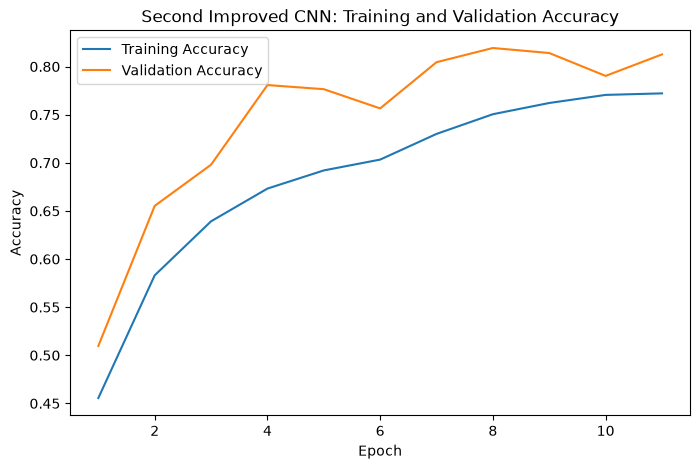

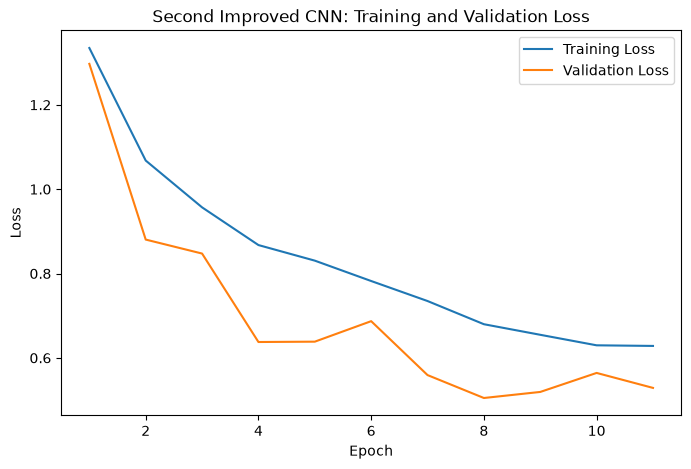

In [ ]:
# Loading the saved training history for my second improved CNN.
improved_history_df_2 = pd.read_csv( "improved_history_2.csv")

# Identifying the number of completed training epochs.
epochs = range( 1, len( improved_history_df_2) + 1)

# Plotting training and validation accuracy. [11, 62]
plt.figure( figsize=( 8, 5))

plt.plot( epochs, improved_history_df_2[ "accuracy"], label="Training Accuracy")
plt.plot( epochs, improved_history_df_2[ "val_accuracy"], label="Validation Accuracy")

plt.title( "Second Improved CNN: Training and Validation Accuracy")
plt.xlabel( "Epoch")
plt.ylabel( "Accuracy")
plt.legend()
plt.show()

# Plotting training and validation loss. [11, 62]
plt.figure( figsize=( 8, 5))

plt.plot( epochs, improved_history_df_2[ "loss"], label="Training Loss")
plt.plot( epochs, improved_history_df_2[ "val_loss"], label="Validation Loss")

plt.title( "Second Improved CNN: Training and Validation Loss")
plt.xlabel( "Epoch")
plt.ylabel( "Loss")
plt.legend()
plt.show()

#### Interpretation

The Second Improved CNN produced more consistent results for both training and validation compared to the First Improved CNN.

The training accuracy rose steadily. The maximum value for the validation accuracy was 81.93%, achieved in epoch 8.

The validation loss was significantly reduced across training. The lowest value obtained for the validation loss was 0.5049 in epoch 8. There were minor fluctuations in the validation loss afterwards. However, early stopping was used to avoid unnecessary training and the weights from epoch 8 were restored.

A significant difference between training and validation accuracy was not observed in the Second Improved CNN, as was observed in the Baseline CNN. The validation accuracy was generally higher than the training accuracy. This may be attributed to the application of dropout and data augmentation during training [16].

It can be inferred that the Second Improved CNN displayed fewer signs of overfitting and had better generalisation compared to the Baseline CNN.

### 11.6 Interpret Improvements

#### Changes Introduced

My Baseline CNN suffered from overfitting. It performed well on the training set (98.96%) but had poorer performance on the validation set (80.46%).

I then implemented early stopping, dropout, global average pooling, batch normalisation and data augmentation in the hope of reducing overfitting. The First Improved CNN still performed poorly on the validation set (65.67%).

I then created a Second Improved CNN which used augmentation, dropout and early stopping but increased the number of parameters compared to the First Improved CNN and removed batch normalisation.

#### Validation Performance

The Second Improved CNN had a precision of 82.29%, recall of 82.09%, F1-score of 82.04%, accuracy of 81.93% and performed 1.47 percentage points better on the validation set than the Baseline CNN’s final performance.

#### Overfitting

The Second Improved CNN had a smaller difference between training and validation accuracy and more consistent validation performance when compared with the Baseline CNN. The validation loss had also reduced to 0.5049, which suggests less overfitting occurred.

#### Conclusion

The Second Improved CNN had the best results on the validation set and also appeared to generalise better. All three models will be compared in Section 12 and then a preferred model will be selected.

## 12. Model Comparison and Final Evaluation

I will compare my Baseline CNN to both my First Improved CNN and Second Improved CNN based on validation loss, validation accuracy, precision, recall and F1-score.

I will then choose the best model based on classification performance and generalisation.

I will then test the chosen model on the test data that was not used during training or validation.

The chosen model will then be saved for later use.

### 12.1 Comparing Models

I will compare my Baseline CNN to both my First Improved CNN and Second Improved CNN based on validation loss, validation accuracy, precision, recall and F1-score.

I will use the same validation data and the same evaluation metrics so that the comparison can be made fairly.

I will then determine which model performed the best at classification before picking my final model.

In [ ]:
# Loading my three previously trained CNN models. [63]
baseline_model = keras.models.load_model( "baseline_cnn_retrained.keras")
improved_model = keras.models.load_model( "improved_cnn.keras")
improved_model_2 = keras.models.load_model( "improved_cnn_2.keras")

print( "All three trained CNN models loaded successfully.")

All three trained CNN models loaded successfully.


In [ ]:
# Calculating validation loss and accuracy for all three trained models. [68]
baseline_loss, val_accuracy = baseline_model.evaluate( val_ds, verbose=0)
improved_loss, improved_accuracy = improved_model.evaluate( val_ds, verbose=0)
improved_loss_2, improved_accuracy_2 = improved_model_2.evaluate( val_ds, verbose=0)

# Generating predictions for all three models. [68]
baseline_predictions = baseline_model.predict( val_ds, verbose=0)
improved_predictions = improved_model.predict( val_ds, verbose=0)
improved_predictions_2 = improved_model_2.predict( val_ds, verbose=0)

# Selecting the predicted category for each image. [64]
baseline_labels = np.argmax( baseline_predictions, axis=1)
improved_labels = np.argmax( improved_predictions, axis=1)
improved_labels_2 = np.argmax( improved_predictions_2, axis=1)

# Calculating precision, recall and F1-score for each model. [65]
val_precision = precision_score( val_true_labels, baseline_labels, average="macro", zero_division=0)
val_recall = recall_score( val_true_labels, baseline_labels, average="macro", zero_division=0)
val_f1 = f1_score( val_true_labels, baseline_labels, average="macro", zero_division=0)

improved_precision = precision_score( val_true_labels, improved_labels, average="macro", zero_division=0)
improved_recall = recall_score( val_true_labels, improved_labels, average="macro", zero_division=0)
improved_f1 = f1_score( val_true_labels, improved_labels, average="macro", zero_division=0)

improved_precision_2 = precision_score( val_true_labels, improved_labels_2, average="macro", zero_division=0)
improved_recall_2 = recall_score( val_true_labels, improved_labels_2, average="macro", zero_division=0)
improved_f1_2 = f1_score( val_true_labels, improved_labels_2, average="macro", zero_division=0)

# Creating a table comparing the three CNN models. [70]
comparison_df = pd.DataFrame( {
    "Model": [ "Baseline CNN", "First Improved CNN", "Second Improved CNN"],
    "Accuracy": [ val_accuracy, improved_accuracy, improved_accuracy_2],
    "Loss": [ baseline_loss, improved_loss, improved_loss_2],
    "Precision": [ val_precision, improved_precision, improved_precision_2],
    "Recall": [ val_recall, improved_recall, improved_recall_2],
    "F1-score": [ val_f1, improved_f1, improved_f1_2]
})

# Displaying the results rounded to four decimal places.
print( comparison_df.round( 4).to_string( index=False))

              Model  Accuracy   Loss  Precision  Recall  F1-score
       Baseline CNN    0.8046 1.4256     0.8121  0.8044    0.8035
 First Improved CNN    0.6567 0.8468     0.7170  0.6630    0.6389
Second Improved CNN    0.8193 0.5049     0.8229  0.8209    0.8204


#### Comparison Findings

My Second Improved CNN produced the best results on validation data. It had the lowest validation loss (0.5049), an accuracy of 81.93% and an F1-score of 82.04%.

The Baseline CNN did also perform reasonably well (80.46% accuracy), however, there was clear evidence of overfitting. The First Improved CNN had the lowest accuracy (65.67%).

The Second Improved CNN therefore provided the best trade-off between classification performance and generalisation. This CNN is therefore the most suitable to use as the final model.

### 12.2 Visualising Model Comparisons

I will create a bar chart displaying the F1-score and validation accuracy for each of my three CNN models.

I will use these to assess the balance between precision and recall and the overall classification performance.

I will also use this visualisation to determine which model performs the best on the validation set.

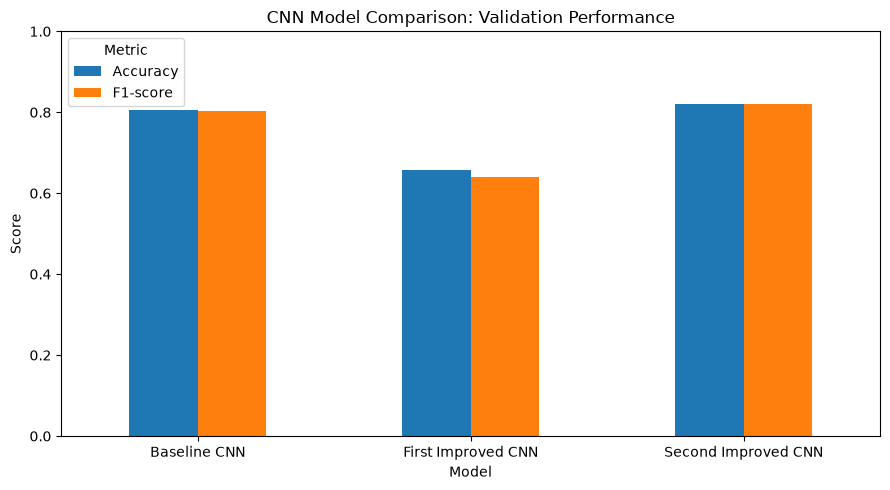

In [59]:
# Selecting the validation metrics I want to compare.
chart_data = comparison_df.set_index( "Model")[ [ "Accuracy", "F1-score"]]

# Creating a bar chart comparing the three CNN models. [71]
chart_data.plot( kind="bar", figsize=( 9, 5))

plt.title( "CNN Model Comparison: Validation Performance")
plt.xlabel( "Model")
plt.ylabel( "Score")
plt.ylim( 0, 1)
plt.xticks( rotation=0)
plt.legend( title="Metric")
plt.tight_layout()
plt.show()

#### Model Comparison Interpretation

My bar chart shows that the second improved CNN achieved the highest validation accuracy (81.93%) and F1-score (82.04%).

The baseline CNN performed second best, while the first improved CNN achieved the lowest scores.

These results suggest that the second improved CNN provides the strongest overall classification performance and is the most suitable candidate for final evaluation.

### 12.3 Selecting Final Model

I selected my second improved CNN as the final model because it achieved the strongest validation performance across all five evaluation metrics.

The model achieved 81.93% validation accuracy, 82.04% F1-score and the lowest validation loss of 0.5049.

It also showed less evidence of overfitting than the baseline CNN, suggesting better generalisation.

The comparison was not completely equal because my second improved CNN used early stopping to restore its best weights, while my baseline CNN was evaluated after its final epoch. My baseline CNN reached its highest validation accuracy of 81.12% at epoch 10, so the improvement in accuracy was relatively small. However, my second improved CNN achieved a lower validation loss and showed less evidence of overfitting.

Based on these results, I will evaluate the second improved CNN on the previously untouched test dataset to assess its performance on unseen images.

### 12.4 Final Test Evaluation

I will test my Second Improved CNN on the previously unused test data (2,997 images).

I will measure the test accuracy, test loss, precision, recall and F1-score. I will also create a confusion matrix and a classification report to look at the performance on the six image categories.

I will use this to assess how well my final model generalises to new images.

In [60]:
# Evaluating my selected CNN on the untouched test dataset. [68]
test_loss, test_accuracy = improved_model_2.evaluate( test_ds, verbose=0)

# Generating predictions for the test images. [68]
test_predictions = improved_model_2.predict( test_ds, verbose=0)
test_predicted_labels = np.argmax( test_predictions, axis=1) # [64]

# Obtaining the actual test labels. [31]
test_true_labels = np.concatenate( [
    labels.numpy() for images, labels in test_ds
])

# Calculating the final classification metrics. [65]
test_precision = precision_score( test_true_labels, test_predicted_labels, average="macro", zero_division=0)
test_recall = recall_score( test_true_labels, test_predicted_labels, average="macro", zero_division=0)
test_f1 = f1_score( test_true_labels, test_predicted_labels, average="macro", zero_division=0)

# Displaying my final test results.
print( f"Test Accuracy: { test_accuracy:.2%}")
print( f"Test Loss: { test_loss:.4f}")
print( f"Test Precision: { test_precision:.2%}")
print( f"Test Recall: { test_recall:.2%}")
print( f"Test F1-score: { test_f1:.2%}")

# Displaying the classification results for each image category. [65]
print( "\nClassification Report:")
print( classification_report( test_true_labels, test_predicted_labels, target_names=class_names, zero_division=0))

Test Accuracy: 83.05%
Test Loss: 0.4897
Test Precision: 83.24%
Test Recall: 83.25%
Test F1-score: 83.16%

Classification Report:
              precision    recall  f1-score   support

   buildings       0.80      0.79      0.80       436
      forest       0.97      0.95      0.96       474
     glacier       0.81      0.76      0.78       552
    mountain       0.81      0.75      0.78       525
         sea       0.79      0.85      0.82       510
      street       0.81      0.90      0.85       500

    accuracy                           0.83      2997
   macro avg       0.83      0.83      0.83      2997
weighted avg       0.83      0.83      0.83      2997



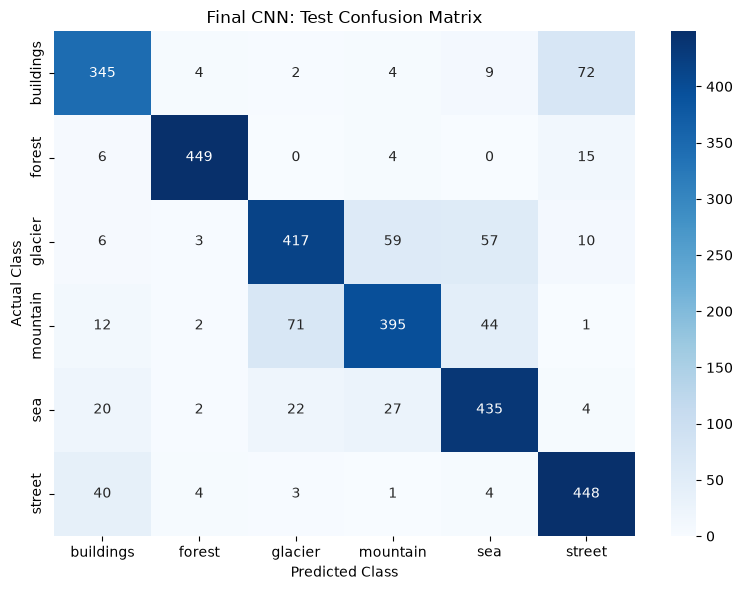

In [ ]:
# Calculating the confusion matrix for my final CNN. [34]
test_cm = confusion_matrix( test_true_labels, test_predicted_labels)

# Visualising the classification results. [72]
plt.figure( figsize=( 8, 6))

sns.heatmap( test_cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)

plt.title( "Final CNN: Test Confusion Matrix")
plt.xlabel( "Predicted Class")
plt.ylabel( "Actual Class")
plt.tight_layout()
plt.show()

#### Final Test Interpretation

My final CNN attained 83.05% accuracy on the test set, 83.24% precision, 83.25% recall and an F1-score of 83.16%.

This is slightly higher than the results attained on the validation set, which suggests a decent level of generalisation to new images.

From the confusion matrix, it can be seen that forest images were classified the most accurately, with 95% recall. Images of glaciers and mountains, as well as buildings and streets, were sometimes mixed up.

My final CNN performed fairly well at classifying the images, but there were still some classification errors.

### 12.5 Saving the Final Model

I will save my selected second improved CNN so that it can be reused without retraining.

Saving the model preserves its trained weights and architecture, allowing it to classify new images in the future [63].

In [ ]:
# Saving my selected CNN for future use. [63]
improved_model_2.save( "final_cnn.keras")

# Confirming that the model has been saved.
print( "Final CNN saved successfully as final_cnn.keras")

#### Potential Uses and Limitations

My saved CNN could be used to automatically classify images into six categories: buildings, forests, glaciers, mountains, seas and streets.

However, with a test accuracy of 83.05%, some misclassification remains, particularly between visually similar categories such as glaciers and mountains.

The model was trained on a specific dataset, so further testing would be necessary before using it in real-world applications.

## 13. Conclusion

In this final section, I will summarise the performance of my CNN image classification project, discuss its main findings and evaluate whether I achieved my objectives.

I will also consider the limitations of my model and identify possible areas for future improvement.

### 13.1 Summary and Key Findings

The objective of my project was to develop and evaluate a Convolutional Neural Network (CNN) capable of classifying images into six categories: buildings, forests, glaciers, mountains, seas and streets.

Three CNNs were created and their performance measured using loss, precision, recall, F1-score and validation accuracy.

My Second Improved CNN performed the best, achieving 83.24% precision, 83.25% recall, an F1-score of 83.16% and 83.05% accuracy on the test set.

The final model displayed reasonable performance on images not seen during training but did misclassify some visually similar categories such as mountains and glaciers.

I have successfully completed the aim of my project by creating a CNN that can classify images into the six categories with a reasonable degree of accuracy. Some areas for improvement have also been identified.

### 13.2 Limitations and Future Improvements

The final CNN produced 83.05% accuracy on the test data, but there are a number of limitations with the current model.

1) Dataset Limitations: The images used in the model are from the Intel Image Classification dataset, which has only six image categories. This means the model can only identify images within these categories and will not be able to identify images outside of them.

2) Classification Errors: Some images which are similar to one another, such as mountains and glaciers, and streets and buildings, were misclassified by the model.

3) Generalisation: The CNN produces good results on the test images but may produce poorer results when classifying images from different lighting conditions, environments or image sources.

4) Facial Recognition: Facial recognition is not currently supported by the model. The model was trained to classify scenery rather than human faces. A suitable facial image dataset would need to be used with appropriate labels and additional training to implement facial recognition.

5) Future Improvements: A more varied and larger dataset could be used with the model. Different CNN architectures could also be tested. Transfer learning using a pretrained model could also be used.

These improvements could aid generalisation to new images and could improve classification accuracy.

This project has illustrated the development, testing and improvement of a CNN used for image classification. There are some limitations with the model, but the final implementation has produced acceptable results on unseen images. This shows the effectiveness of CNNs for image classification and provides a foundation for further improvements.

## Reference list

[1]	P. Bansal, ‘Intel Image Classification’, www.kaggle.com. [Online]. Available: https://www.kaggle.com/datasets/puneet6060/intel-image-classification

[2]	GeeksforGeeks, ‘Convolutional Neural Network (CNN) in Tensorflow’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/deep-learning/convolutional-neural-network-cnn-in-tensorflow/

[3]	N. Selvaraj, ‘Pyspark Tutorial: Getting Started With Pyspark’, Datacamp.com. [Online]. Available: https://www.datacamp.com/tutorial/pyspark-tutorial-getting-started-with-pyspark

[4]	I. Belcic and C. Stryker, ‘What is Supervised Learning?’, Ibm.com. [Online]. Available: https://www.ibm.com/think/topics/supervised-learning?

[5]	Rukshan Pramoditha, ‘How RGB and Grayscale Images Are Represented in NumPy Arrays? | Towards Data Science’, Towards Data Science. [Online]. Available: https://towardsdatascience.com/exploring-the-mnist-digits-dataset-7ff62631766a/

[6]	IBM, ‘What is Data Quality?’, Ibm.com. [Online]. Available: https://www.ibm.com/think/topics/data-quality

[7]	IBM, ‘Data Leakage Machine Learning’, Ibm.com. [Online]. Available: https://www.ibm.com/think/topics/data-leakage-machine-learning

[8]	GeeksforGeeks, ‘Handling Imbalanced Data for Classification’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/machine-learning/handling-imbalanced-data-for-classification/

[9]	S. Dodge and L. Karam, ‘Understanding How Image Quality Affects Deep Neural Networks’, 2016. [Online]. Available: https://arxiv.org/pdf/1604.04004

[10]	GeeksforGeeks, ‘What Is Exploratory Data Analysis?’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/data-analysis/what-is-exploratory-data-analysis/

[11]	TensorFlow, ‘Image Classification | TensorFlow Core’, TensorFlow. [Online]. Available: https://www.tensorflow.org/tutorials/images/classification

[12]	scikit-learn, ‘Common Pitfalls and Recommended Practices’, scikit-learn. [Online]. Available: https://scikit-learn.org/stable/common_pitfalls.html

[13]	Z. Xian, R. Huang, D. Towey, and C. Yue, ‘Convolutional Neural Network Image Classification Based on Different Color Spaces’, Tsinghua Science and Technology, vol. 30, no. 1, pp. 402–417, 2024, doi: 10.26599/tst.2024.9010001.

[14]	GeeksforGeeks, ‘Splitting Data for Machine Learning Models’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/machine-learning/splitting-data-for-machine-learning-models/

[15]	IBM, ‘Convolutional Neural Networks’, Ibm.com. [Online]. Available: https://www.ibm.com/think/topics/convolutional-neural-networks

[16]	TensorFlow, ‘Data Augmentation | TensorFlow Core’, TensorFlow. [Online]. Available: https://www.tensorflow.org/tutorials/images/data_augmentation

[17]	I. Belcic and C. Stryker, ‘What Is Feature Selection? | IBM’, Ibm.com. [Online]. Available: https://www.ibm.com/think/topics/feature-selection

[18]	GeeksforGeeks, ‘ReLU Activation Function in Deep Learning’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/deep-learning/relu-activation-function-in-deep-learning/

[19]	GeeksforGeeks, ‘Softmax Activation Function in Neural Networks’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/deep-learning/the-role-of-softmax-in-neural-networks-detailed-explanation-and-applications/

[20]	GeeksforGeeks, ‘Introduction to Adam Optimizer’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/deep-learning/adam-optimizer/

[21]	GeeksforGeeks, ‘What Is Sparse Categorical Crossentropy’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/machine-learning/what-is-sparse-categorical-crossentropy/

[22]	GeeksforGeeks, ‘Batch Size in Neural Network’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/deep-learning/batch-size-in-neural-network/

[23]	GeeksforGeeks, ‘Evaluation Metrics in Machine Learning’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/machine-learning/metrics-for-machine-learning-model/

[24]	GeeksforGeeks, ‘What Is CrossEntropy Loss Function?’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/machine-learning/what-is-cross-entropy-loss-function/

[25]	GeeksforGeeks, ‘Training and Validation Loss in Deep Learning’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/deep-learning/training-and-validation-loss-in-deep-learning/

[26]	D. Radečić, ‘Overfitting Vs. Underfitting: A Practical Guide to Model Diagnostics’, DataCamp. [Online]. Available: https://www.datacamp.com/tutorial/overfitting-vs-underfitting

[27]	GeeksforGeeks, ‘Dropout Regularization in Deep Learning’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/deep-learning/dropout-regularization-in-deep-learning/

[28]	GeeksforGeeks, ‘Batch Normalization in Deep Learning’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/deep-learning/batch-normalization-in-deep-learning-2/

[29]	GeeksforGeeks, ‘Regularization by Early Stopping’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/machine-learning/regularization-by-early-stopping/

[30]	IBM, ‘Learning Rate’, Ibm.com. [Online]. Available: https://www.ibm.com/think/topics/learning-rate

[31]	TensorFlow, ‘Load Images With Tf.Data | TensorFlow Core’, TensorFlow. [Online]. Available: https://www.tensorflow.org/tutorials/load_data/images

[32]	M. Waskom, ‘An Introduction to Seaborn — Seaborn 0.12.1 Documentation’, seaborn.pydata.org. [Online]. Available: https://seaborn.pydata.org/tutorial/introduction.html

[33]	ApacheSpark, ‘Quickstart: DataFrame — PySpark Master Documentation’, spark.apache.org. [Online]. Available: https://spark.apache.org/docs/latest/api/python/getting_started/quickstart_df.html

[34]	scikit-learn, ‘Confusion Matrix — Scikit-Learn 0.22 Documentation’, Scikit-learn.org. [Online]. Available: https://scikit-learn.org/stable/auto_examples/model_selection/plot_confusion_matrix.html

[35]	Fall 2024 Applied Data Science with Python, ‘Tutorial 8 - TensorFlow’, Fall 2024 Applied Data Science with Python (ReadTheDocs). [Online]. Available: https://fall-2024-applied-data-science-with-python.readthedocs.io/en/latest/Lectures/Tutorials/Tutorial_8-TensorFlow/Tutorial_8-TensorFlow.html

[36]	‘Use a GPU | TensorFlow Core’, TensorFlow. [Online]. Available: https://www.tensorflow.org/guide/gpu

[37]	‘Pyspark.Sql.SparkSession — PySpark 3.4.0 Documentation’, spark.apache.org. [Online]. Available: https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.SparkSession.html

[38]	‘How to Reduce the Verbosity of Spark’s Runtime Output? - Stack Overflow’, Freedombox.rocks. [Online]. Available: https://kaweah.freedombox.rocks/kiwix/content/stackoverflow.com_en_all_2023-11/questions/28189408/how-to-reduce-the-verbosity-of-spark-s-runtime-output

[39]	‘Read Binary Files | Databricks on AWS’, Databricks.com. [Online]. Available: https://docs.databricks.com/aws/en/query/formats/binary

[40]	‘Pyspark.Sql.DataFrame.Show — PySpark 4.0.1 Documentation’, Apache.org. [Online]. Available: https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.show.html

[41]	‘pyspark.sql.functions.regexp_extract’, PySpark. [Online]. Available: https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.functions.regexp_extract.html

[42]	‘Regular Expression HOWTO — Python 3.15.2 Documentation’, Python.org. [Online]. Available: https://docs.python.org/3/howto/regex.html

[43]	‘pyspark.sql.DataFrame.distinct’, PySpark. [Online]. Available: https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.distinct.html

[44]	‘Pyspark.Sql.DataFrame.unionByName — PySpark 4.0.1 Documentation’, Apache.org. [Online]. Available: https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.unionByName.html

[45]	‘Apache Spark - How to Find Count of Null and Nan Values for Each Column in a PySpark Dataframe Efficiently?’, Stack Overflow. [Online]. Available: https://stackoverflow.com/questions/44627386/how-to-find-count-of-null-and-nan-values-for-each-column-in-a-pyspark-dataframe

[46]	Durga Gadiraju, ‘Dealing With Nulls While Filtering — Mastering Pyspark’, Itversity.com. [Online]. Available: https://pyspark.itversity.com/05_basic_transformations/10_dealing_with_nulls_while_filtering.html

[47]	‘Pyspark.Sql.Column.Isin — PySpark 4.3.0 Documentation’, Apache.org. [Online]. Available: https://spark.apache.org/docs/latest/api/python/reference/pyspark.sql/api/pyspark.sql.Column.isin.html

[48]	‘Calculating percentage of total count for groupBy using pyspark’, StackOverflow. [Online]. Available: https://stackoverflow.com/questions/52283751/calculating-percentage-of-total-count-for-groupby-using-pyspark/52285108

[49]	Suhith Illesinghe, ‘How to Create a Graph With PySpark and Matplotlib’, Mustard Seeds Group. [Online]. Available: https://www.mustardseedsgroup.com.au/insights/pyspark/how-to-create-a-graph-with-pyspark/


[50]	Pillow, ‘Image Module — Pillow (PIL Fork) 13.0.0 Documentation’, Readthedocs.io. [Online]. Available: https://pillow.readthedocs.io/en/stable/reference/Image.html

[51]	‘Pandas.Series.Value_Counts — Pandas 3.1.1 Documentation’, pandas.pydata.org. [Online]. Available: https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html

[52]	GeeksforGeeks, ‘Finding Duplicate Files With Python’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/python/finding-duplicate-files-with-python/

[53]	‘Pandas.DataFrame.Duplicated — Pandas 3.1.1 Documentation’, pandas.pydata.org. [Online]. Available: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html

[54]	Betul Mescioglu, ‘Image Processing Tutorial Using Scikit-Image — Manipulating Image Pixels’, Medium. [Online]. Available: https://medium.com/@betulmesci/image-processing-tutorial-using-scikit-image-manipulating-image-pixels-b35be89b95bf

[55]	‘Pandas.DataFrame.Plot.Bar — Pandas 3.1.1 Documentation’, pandas.pydata.org. [Online]. Available: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html

[56]	pandas, ‘Pandas.DataFrame.Drop_Duplicates — Pandas 3.1.1 Documentation’, pandas.pydata.org. [Online]. Available: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html

[57]	‘Pandas.Series.Isin — Pandas 3.1.1 Documentation’, pandas.pydata.org. [Online]. Available: https://pandas.pydata.org/docs/reference/api/pandas.Series.isin.html

[58]	GeeksforGeeks, ‘Pandas.Concat() Function in Python’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/python/pandas-concat-function-in-python/

[59]	‘Substring each element of python data frame’, StackOverflow. [Online]. Available: https://stackoverflow.com/questions/47074884/substring-each-element-of-python-data-frame

[60]	GeeksforGeeks, ‘How to Count Unique Values in a Pandas Groupby Object?’, GeeksforGeeks. [Online]. Available: https://www.geeksforgeeks.org/python/how-to-count-unique-values-in-a-pandas-groupby-object/

[61]	‘tf.Tensor’, TensorFlow. [Online]. Available: https://www.tensorflow.org/api_docs/python/tf/Tensor

[62]	Matplotlib, ‘Matplotlib.Pyplot.Plot — Matplotlib 3.11.2 Documentation’, matplotlib.org. [Online]. Available: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html

[63]	K. Team, ‘Keras Documentation: Saving & Serialization’, Keras.io. [Online]. Available: https://keras.io/api/models/model_saving_apis/

[64]	numpy, ‘Numpy.Argmax — NumPy V2.5 Manual’, numpy.org. [Online]. Available: https://numpy.org/doc/stable/reference/generated/numpy.argmax.html

[65]	Scikit Learn, ‘3.4. Metrics and Scoring: Quantifying the Quality of Predictions — Scikit-Learn 0.22.1 Documentation’, scikit-learn.org. [Online]. Available: https://scikit-learn.org/stable/modules/model_evaluation.html

[66]	pandas, ‘Pandas.DataFrame.To_Csv — Pandas 3.1.1 Documentation’, pandas.pydata.org. [Online]. Available: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html

[67]	Keras Team, ‘Keras Documentation: GlobalAveragePooling2D Layer’, Keras.io. [Online]. Available: https://keras.io/api/layers/pooling_layers/global_average_pooling2d/

[68]	K. Team, ‘Keras Documentation: Model Training APIs’, keras.io. [Online]. Available: https://keras.io/api/models/model_training_apis/

[69]	Keras Team, ‘Keras Documentation: EarlyStopping’, keras.io. [Online]. Available: https://keras.io/api/callbacks/early_stopping/

[70]	pandas, ‘Pandas.DataFrame — Pandas 3.1.1 Documentation’, pandas.pydata.org. [Online]. Available: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html

[71]	Matplotlib Development Team, ‘Grouped Bar Chart With Labels’, Matplotlib. [Online]. Available: https://matplotlib.org/stable/gallery/lines_bars_and_markers/barchart.html

[72]	M. Waskom, ‘Seaborn.Heatmap — Seaborn 0.13.2 Documentation’, seaborn.pydata.org. [Online]. Available: https://seaborn.pydata.org/generated/seaborn.heatmap.html

